# 🦋 Week 2 — Fitting the emergence rate in 1D

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SwRI-IDEA-Lab/butterflai2/blob/main/weeks/week_02/02_rate_1d.ipynb)

> Can we recover the sunspot-number bell curve as the rate of a Poisson process?

Week 1 ended in a dead end, and it was an instructive one. The Fano factor said the data is overdispersed
by a factor of seventy, but we had predicted something like that before looking, purely because the
emergence rate varies by an order of magnitude across a wing. To turn F(Δ) into a statement about the Sun
we had to compare against a null model with "the same rate", and we built that rate by smoothing — which
buried the answer under a choice of bandwidth.

The way out is to stop smoothing and start *fitting*. This week we write down a rate λ(s), fit it to the
event times by maximum likelihood, and then test it with a procedure that has no free bandwidth at all.

Three things make this the hinge of Phase A:

1. *The likelihood moves onto event times.* Last week's score was a density over latitude, in nats per
   event. This week's is over *when* things happened, in nats per hemicycle-year — and that change of
   units is what finally lets a score reward a model for getting the number of events right.
2. *Every model from here on is fitted with this same loss.* The expression you implement in Task 10 is,
   term for term, the loss that Week 5's neural latent field is trained on. Only λ changes.
3. *This is the first notebook that has to respect the withheld cycles.* Three whole cycles are sealed
   for the final reveal, starting now.

What you will produce by the end:

1. A point-process log-likelihood on event times, with its integral term computed by quadrature.
2. A fitted emergence rate λ(s) for each of the 18 development hemispheric cycles.
3. A fitter you have *verified*, by simulating from known parameters and recovering them — and then broken
   on purpose, two different ways, to see what each failure looks like.
4. A goodness-of-fit test with no free bandwidth, and an answer to how much the shape of a wing really
   varies from cycle to cycle.

Section 1 is given code with no tasks: Week 1 compressed into a handful of cells. Tasks 10–19 are yours.

---
## How to work this notebook

Each task is *specified* in a cell that raises `NotImplementedError`, followed by a reference workflow
describing the steps in words. Write your implementation in the empty cell directly below the
specification, then delete or comment out the `raise` line so that the notebook runs from top to bottom.
Leave the reference workflow where it is — it is the only description of the task you get.

Before you implement anything, open a session with the tutor prompt in `vocal_prompt_week02.md`: paste
that file, then this whole notebook, then your first question. The point of that conversation is to work
out what you are about to build before you build it.

Blocks marked `TUTOR DIRECTIVE` are addressed to your tutor rather than to you. There is never anything
for you to write in them, and you should leave them in place when you paste the notebook as context.

```text
TUTOR DIRECTIVE — session opening.

The student has pasted this entire notebook as context. Nothing in it has been run: every task raises
NotImplementedError, each is followed by a reference workflow, and the empty cell beneath each task is
the student's own workspace, not an omission for you to fill in. This session happens before they
implement anything, and its purpose is the conversation they have about what they are going to build.

So: do not write their task code, and do not walk them through a reference workflow step by step. Four
further TUTOR DIRECTIVE blocks appear later, at Sections 2, 5, 6 and 7, and each names the destinations
the conversation has to reach at that point. Everything else in the notebook is material you may draw on.

This week's targets are the terms set in bold in the notebook text, each bolded where it is first
introduced. The student has therefore read a definition of every one of them, and has almost certainly
used none of them in a sentence of their own. Treat them all as unused: having read a term here does
not put it on the table, and you still have to introduce it yourself before asking them to deploy it.

The student should be pasting their Week 01 HANDOFF after this prompt. If they do, carry its levels and
anchors forward per domain name; the domain names are unchanged from last week. If they do not, ask once
whether they have it, then proceed without it rather than pressing.
```

In [10]:
# ── ButterflAI 2.0 standard setup — run this first ─────────────────────────
import os, sys, random, subprocess
from pathlib import Path

REPO_URL = "https://github.com/SwRI-IDEA-Lab/butterflai2.git"

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    REPO = Path("/content/butterflai2")
    if REPO.exists():
        subprocess.run(["git", "-C", str(REPO), "pull", "--ff-only"], check=False)
    else:
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(REPO)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                    str(REPO / "requirements.txt")], check=True)
else:
    # Local: walk up from the notebook's folder to the repository root.
    REPO = next((p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / "legacy" / "butterflAI_model.py").exists()), None)
    if REPO is None:
        raise RuntimeError("Could not find the butterflai2 repository root. "
                           "Open this notebook from inside your clone.")

DATA = REPO / "data"
DERIVED = DATA / "derived"
DERIVED.mkdir(exist_ok=True)
LEGACY = REPO / "legacy"
sys.path.insert(0, str(LEGACY))   # enables: from butterflAI_model import ButterflAIModel

SEED = 42
random.seed(SEED)
import numpy as np
np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    DEVICE = torch.device("cuda" if torch.cuda.is_available()
                          else "mps" if torch.backends.mps.is_available() else "cpu")
except ImportError:
    DEVICE = "cpu"

print(f"🦋 ButterflAI 2.0 | {'Colab' if IN_COLAB else 'local'} | repo: {REPO} | device: {DEVICE}")

🦋 ButterflAI 2.0 | Colab | repo: /content/butterflai2 | device: cpu


In [11]:
# Everything else this notebook needs. Phase A is numpy and scipy; PyTorch arrives in Week 5.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid, cumulative_trapezoid
from scipy.optimize import minimize
from scipy.stats import kstest

from butterflAI_model import ButterflAIModel, A_REF

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.titlesize": 11, "figure.titlesize": 12})

# ── Week 1's constants, re-declared. Notebooks are self-contained. ──
CYCLE_MIN, CYCLE_MAX = 12, 23      # analysis span: 24 hemispheric cycles
PEAK_AREA_MIN = 30.0               # MSH — drops pores and the smallest groups
AMP_AREA_MIN = 50.0                # MSH — ButterflAI 1.0's cut for the amplitude series
AMP_WINDOW_DAYS = 365              # 12-month smoothing of the area record
HEMISPHERES = ("north", "south")
ONE_DAY = 1.0 / 365.25             # one day, in years — our time unit everywhere

# ── This week's constants. Each is a decision; Section 2 and Section 3 justify them. ──
S_A, S_B = -6.0, 11.0              # the observation window in s, in years. Fixed program-wide.
N_MESH = 4001                      # quadrature nodes across that window
S_MESH = np.linspace(S_A, S_B, N_MESH)
MESH_STEP_DAYS = (S_B - S_A) / (N_MESH - 1) / ONE_DAY
WINDOW_YEARS = S_B - S_A

print(f"observation window : s from {S_A:+.1f} to {S_B:+.1f} yr  ({WINDOW_YEARS:.0f} yr per hemicycle)")
print(f"quadrature mesh    : {N_MESH} nodes, spacing {MESH_STEP_DAYS:.2f} days "
      f"(finer than the catalog's 1-day quantization)")

observation window : s from -6.0 to +11.0 yr  (17 yr per hemicycle)
quadrature mesh    : 4001 nodes, spacing 1.55 days (finer than the catalog's 1-day quantization)


---
## 1 · Previously: the emergence table and the clock `s`

*Given code — no tasks. This is Week 1's Tasks 3 and 4 plus the pieces of Section 1 they depend on. If you
did Week 1, skim it and check the numbers match what you got.*

Recall the three decisions this rests on. An *event* is a sunspot group's *first observation*, not its
peak-area observation: peak area is the right proxy for *where* a group is and the wrong one for *when* it
appeared. The analysis set is cycles 12–23 with peak corrected area above 30 MSH, which gives 22,122
events over 24 hemispheric cycles. And time is `s`, the years since that wing's mean latitude crossed 15°
on its way to the equator — a pure shift of each wing's clock, never a rescaling.

One assumption carries over and is worth restating because this week divides by time: *exposure is
treated as complete.* The catalog has no observing-day record, and an exposure series rebuilt from the
original logs gives a mean observed fraction of about 0.99 for cycles 12–23, so every rate below is
roughly 1% low and we do not correct for it.

In [12]:
# Given: the catalog, with a decimal-year time column.
CATALOG = DATA / "composite_sunspot_groups_daily_measurements_10_23.csv"
daily = pd.read_csv(CATALOG)


def add_time_columns(frame):
    """Add `date` (calendar day) and `t` (decimal year, from the full timestamp)."""
    stamp = pd.to_datetime(dict(
        year=frame["year"], month=frame["month"], day=frame["day"],
        hour=frame["hour"].fillna(12).astype(int),
        minute=frame["minute"].fillna(0).astype(int),
        second=frame["second"].fillna(0).astype(int),
    ))
    day_of_year = (stamp.dt.dayofyear - 1 + stamp.dt.hour / 24.0
                   + stamp.dt.minute / 1440.0 + stamp.dt.second / 86400.0)
    year_length = np.where(stamp.dt.is_leap_year, 366.0, 365.0)
    frame = frame.copy()
    frame["date"] = stamp.dt.normalize()
    frame["t"] = stamp.dt.year + day_of_year / year_length
    return frame


daily = add_time_columns(daily)
obs = daily[daily["uniqueID"].notna()].copy()
print(f"catalog rows {len(daily):,} · rows with a group id {len(obs):,} · "
      f"distinct groups {obs['uniqueID'].nunique():,}")

catalog rows 314,648 · rows with a group id 249,752 · distinct groups 46,110


In [13]:
# Given: 1.0's groups-at-peak-area table. We need it for the 15-degree crossing epochs and for the
# amplitude series, both of which are expressed in 1.0's convention.
peak_rows = obs.loc[obs.groupby("uniqueID")["correctedArea"].idxmax()]
peak_rows = peak_rows[peak_rows["latitude"].notna() & peak_rows["CYCLE"].notna()]

groups10 = pd.DataFrame({
    "date": peak_rows["date"].to_numpy(),
    "t": peak_rows["t"].to_numpy(),
    "latitude": peak_rows["latitude"].to_numpy(),
    "peak_area": peak_rows["correctedArea"].to_numpy(),
    "cycle": peak_rows["CYCLE"].astype(int).to_numpy(),
})
groups10["hemisphere"] = np.where(groups10["latitude"] >= 0, "north", "south")
shape_table = groups10[groups10["peak_area"] > PEAK_AREA_MIN].copy()

model = ButterflAIModel()
CYCLES = list(range(CYCLE_MIN, CYCLE_MAX + 1))
T0 = {(c, h): model.lookup_t0(c, h) for c in CYCLES for h in HEMISPHERES}
print(f"1.0 peak-area table: {len(groups10):,} groups · above {PEAK_AREA_MIN:.0f} MSH: {len(shape_table):,}")
print(f"15-degree crossing epochs loaded for {len(T0)} hemispheric cycles")

1.0 peak-area table: 45,612 groups · above 30 MSH: 32,080
15-degree crossing epochs loaded for 24 hemispheric cycles


In [14]:
# Given: Week 1's Tasks 3 and 4, as solved functions.
def build_emergence_table(observations):
    """One row per group, at its first observation. Index reset; `uniqueID` is a column."""
    ordered = observations.sort_values("t")
    first = ordered.drop_duplicates("uniqueID", keep="first").set_index("uniqueID")
    by_group = ordered.groupby("uniqueID")

    table = pd.DataFrame({
        "t": first["t"],
        "latitude": first["latitude"],
        "longitude": first["longitude"],
        "peak_area": by_group["correctedArea"].max(),
        "cycle": by_group["CYCLE"].first(),
    })
    table = table[table["cycle"].notna()].copy()
    table["cycle"] = table["cycle"].astype(int)
    table["hemisphere"] = np.where(table["latitude"] >= 0, "north", "south")
    table["abs_latitude"] = table["latitude"].abs()
    return table.reset_index()


def apply_analysis_set(table):
    """Keep cycles CYCLE_MIN..CYCLE_MAX above the area cut, and add t0, s and a hemicycle label."""
    keep = (table["cycle"].between(CYCLE_MIN, CYCLE_MAX)
            & (table["peak_area"] > PEAK_AREA_MIN))
    sel = table[keep].copy()
    sel["t0"] = [T0[(c, h)] for c, h in zip(sel["cycle"], sel["hemisphere"])]
    sel["s"] = sel["t"] - sel["t0"]
    sel["hemicycle"] = sel["cycle"].astype(str) + sel["hemisphere"].str[0].str.upper()
    return sel.sort_values(["hemicycle", "s"]).reset_index(drop=True)


emergences = apply_analysis_set(build_emergence_table(obs))
assert len(emergences) == 22_122, f"expected 22,122 events, got {len(emergences):,}"
print(f"emergence table: {len(emergences):,} events over "
      f"{emergences['hemicycle'].nunique()} hemispheric cycles")

emergence table: 22,122 events over 24 hemispheric cycles


### 1.1 · The development set, and three cycles we are not allowed to look at

From this notebook onward, *cycles 16, 20 and 22 are withheld.* They are sealed for a single final
reveal at the end of the program, and nothing we do between now and then may fit, tune, plot or score
them. That leaves nine cycles — 12, 13, 14, 15, 17, 18, 19, 21, 23 — which is *18 hemispheric cycles*
and 16,611 events. Everything below uses those.

Why whole cycles rather than single hemispheres: Week 5 conditions a model on the *opposite* hemisphere,
and Week 6's history features run in calendar time, where the two hemispheres coincide. Withholding 20N
while training on 20S would hand those models the held-out unit directly.

Two honest caveats, both worth repeating wherever a held-out number is quoted. The withheld cycles were
chosen to span the middle of the amplitude range, so this is not a blind split — it is a *representative*
one, built to catch overfitting to our own validation folds over four weeks of variant selection, not to
test extrapolation. And the guarantee is "never *fitted*, tuned or selected on", not "never seen":
Week 1 plotted all 24 hemicycles, which is harmless because it fitted nothing, but it is disclosed rather
than claimed away.

The two strongest and weakest wings — cycle 19 (strongest) and cycle 14 (weakest) — stay in development
on purpose, so no model ever has to extrapolate in amplitude on the scored set.

In [15]:
# Given: the split, with a guard. Every fit, figure and score below this cell uses `dev`.
WITHHELD_CYCLES = (16, 20, 22)
DEV_CYCLES = tuple(c for c in CYCLES if c not in WITHHELD_CYCLES)

dev = emergences[emergences["cycle"].isin(DEV_CYCLES)].copy().reset_index(drop=True)
DEV_HEMICYCLES = sorted(dev["hemicycle"].unique(), key=lambda h: (int(h[:-1]), h[-1]))

assert not set(dev["cycle"]) & set(WITHHELD_CYCLES), "a withheld cycle reached the development set"
assert len(dev) == 16_611, f"expected 16,611 development events, got {len(dev):,}"
assert len(DEV_HEMICYCLES) == 18

EVENTS = {h: np.sort(g["s"].to_numpy()) for h, g in dev.groupby("hemicycle")}

print(f"development  : cycles {DEV_CYCLES} -> {len(DEV_HEMICYCLES)} hemicycles, {len(dev):,} events")
print(f"withheld     : cycles {WITHHELD_CYCLES} -> sealed, not touched again in this notebook")
print(f"events per hemicycle: {min(map(len, EVENTS.values()))} to {max(map(len, EVENTS.values()))}")
print(f"s spans {dev['s'].min():+.2f} to {dev['s'].max():+.2f} yr, "
      f"inside the window [{S_A:+.1f}, {S_B:+.1f}]")

assert dev["s"].min() > S_A and dev["s"].max() < S_B, "an event falls outside the observation window"

development  : cycles (12, 13, 14, 15, 17, 18, 19, 21, 23) -> 18 hemicycles, 16,611 events
withheld     : cycles (16, 20, 22) -> sealed, not touched again in this notebook
events per hemicycle: 525 to 1590
s spans -4.78 to +8.48 yr, inside the window [-6.0, +11.0]


### 1.2 · The amplitude of each hemispheric cycle

We need one more number per wing, for the plausibility check in Section 7: the cycle's amplitude `A`, the
peak of the 12-month-smoothed total sunspot area of that hemisphere. Section 7 asks whether the rate we
fit to event *times* peaks when the *area* record peaks — two independent measurements of the same Sun.

The recipe is 1.0's, and one detail of it is easy to get wrong by a factor of five: the contributions come
from the *groups-at-peak-area table*, one per group, not from the daily measurements. The average group
is observed on five days, so summing daily rows inflates `A` by about that factor. Units are MSH divided
by `A_REF` = 1000, so real hemispheric cycles run `A` ≈ 0.08 to 0.32.

The smoothed area series necessarily spans all calendar time, including the withheld cycles — it is an
observational record, not a fit, and nothing is selected from it. We extract peaks only for the 18
development hemicycles.

In [16]:
# Given: the amplitude series and its peak inside each development hemicycle's calendar span.
amp_source = shape_table[(shape_table["cycle"] >= CYCLE_MIN)
                         & (shape_table["peak_area"] > AMP_AREA_MIN)]
grid = pd.date_range(amp_source["date"].min(), amp_source["date"].max(), freq="D")

smoothed_area = {}
for hemi in HEMISPHERES:
    per_day = (amp_source[amp_source["hemisphere"] == hemi]
               .groupby("date")["peak_area"].sum()
               .reindex(grid, fill_value=0.0))
    smoothed_area[hemi] = per_day.rolling(AMP_WINDOW_DAYS, center=True,
                                          min_periods=AMP_WINDOW_DAYS // 3).mean()

amp_rows = []
for cyc in DEV_CYCLES:
    cycle_dates = shape_table.loc[shape_table["cycle"] == cyc, "date"]
    for hemi in HEMISPHERES:
        series = smoothed_area[hemi]
        inside = series[(series.index >= cycle_dates.min())
                        & (series.index <= cycle_dates.max())].dropna()
        peak_date = inside.idxmax()
        year_len = 366.0 if peak_date.is_leap_year else 365.0
        amp_rows.append(dict(
            hemicycle=f"{cyc}{hemi[0].upper()}",
            A=float(inside.max()) / A_REF,
            s_peak_area=peak_date.year + (peak_date.dayofyear - 1) / year_len - T0[(cyc, hemi)],
        ))

amplitudes = pd.DataFrame(amp_rows).set_index("hemicycle").loc[DEV_HEMICYCLES]
AMPLITUDE = amplitudes["A"].to_dict()

print(f"A spans {amplitudes['A'].min():.3f} to {amplitudes['A'].max():.3f} "
      f"(legacy/ documents 0.08-0.32)")
print(f"strongest {amplitudes['A'].idxmax()} · weakest {amplitudes['A'].idxmin()}")
print(f"smoothed-area peak in s: {amplitudes['s_peak_area'].min():+.2f} to "
      f"{amplitudes['s_peak_area'].max():+.2f} yr")
assert 0.07 < amplitudes["A"].min() and amplitudes["A"].max() < 0.35, \
    "amplitudes are outside the range 1.0's regressions were fit on — check the MSH/1000 conversion"

A spans 0.079 to 0.315 (legacy/ documents 0.08-0.32)
strongest 19N · weakest 12N
smoothed-area peak in s: -1.01 to +1.82 yr


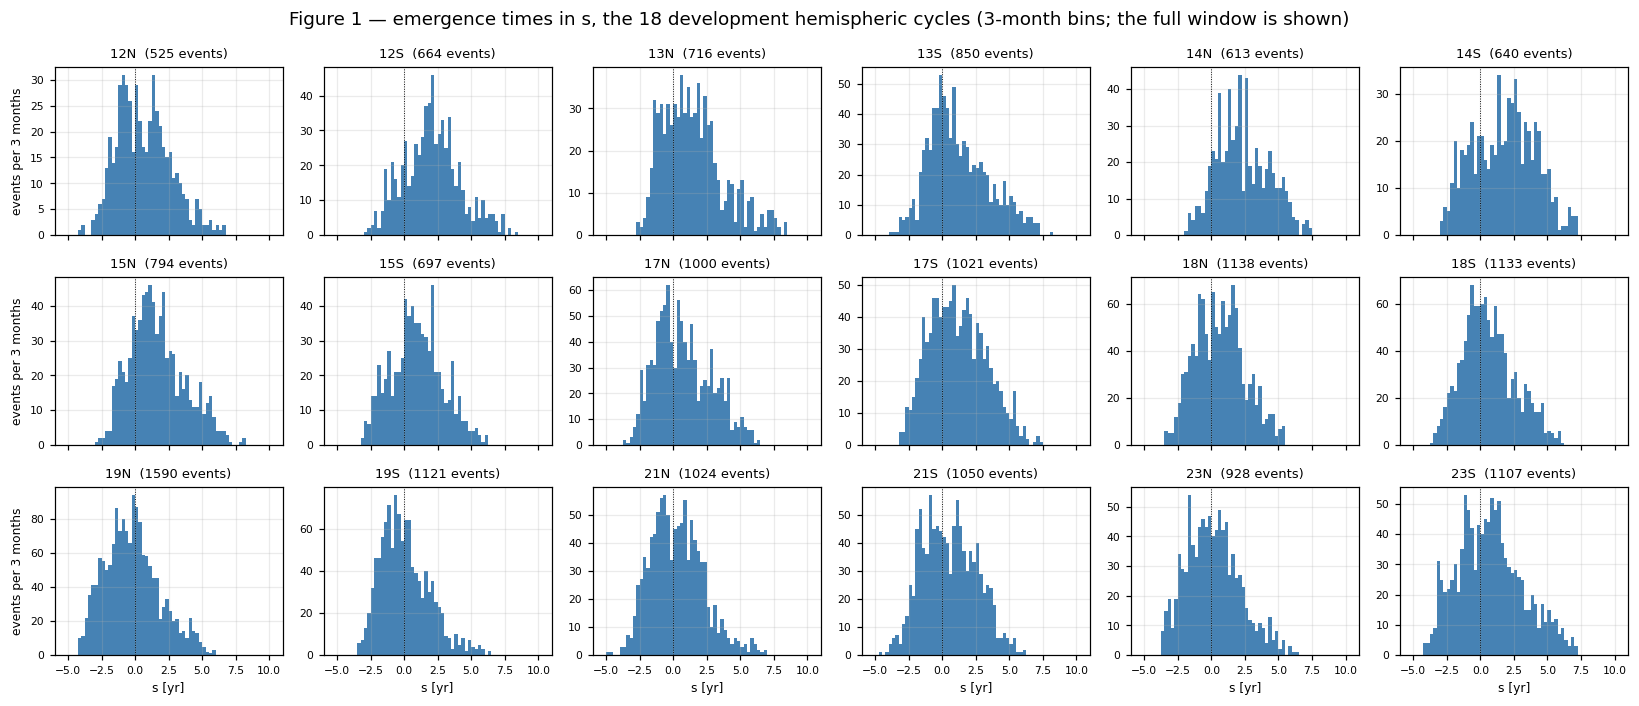

In [17]:
# Given: Figure 1 — what we are about to fit.
fig, axes = plt.subplots(3, 6, figsize=(15, 6.5), sharex=True)
bins = np.arange(S_A, S_B + 0.25, 0.25)

for ax, label in zip(axes.ravel(), DEV_HEMICYCLES):
    ax.hist(EVENTS[label], bins=bins, color="steelblue", edgecolor="none")
    ax.axvline(0.0, color="k", lw=0.6, ls=":")
    ax.set_title(f"{label}  ({len(EVENTS[label])} events)", fontsize=8.5)
    ax.tick_params(labelsize=7)
    ax.set_xlim(S_A, S_B)
for ax in axes[-1, :]:
    ax.set_xlabel("s [yr]", fontsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel("events per 3 months", fontsize=8)
fig.suptitle("Figure 1 — emergence times in s, the 18 development hemispheric cycles "
             "(3-month bins; the full window is shown)")
plt.tight_layout()
plt.show()

Each panel is one realization of the process we are modeling. Read three things off them.

They all have the same gross shape — a slow rise starting a few years before `s` = 0, a maximum somewhere
within a year or two of `s` = 0, and a longer decay. The *heights* differ by a factor of three. And the
bins are noisy: these are counts, so a panel with 600 events has roughly √600 ≈ 25 events of Poisson
scatter spread across its bins, which is most of the wiggle you see.

Notice also how much of the window is empty. Every panel runs over the full 17 years from `s` = −6 to
`s` = +11, and in most of them nothing happens for the first two years and the last four. That emptiness
is data — it is the next section's whole point.

---
## 2 · The likelihood on event times

We are going to model each wing as an **inhomogeneous Poisson process**: a Poisson process whose rate is
allowed to vary with time. It keeps the independence property from Week 1 — what happens in one interval
tells you nothing about any other — and drops the constant rate. That is exactly the right first model
here, because Week 1's one surviving result was that the departure from memorylessness is a few percent at
a one-day scale, while the rate varies by a factor of ten across a wing. The big effect is the rate.

The function that replaces the constant is the **intensity function** λ(s), with units of events per year.
Its meaning is local: λ(s) ds is the expected number of events in the little interval [s, s + ds], and for
a Poisson process that is also the probability of exactly one event there, to first order in ds. When the
process is emergence, λ(s) is the **emergence rate** — the thing ButterflAI 1.0 never had.

### The two terms

Suppose we observe one hemicycle over a window [s_a, s_b] and see events at s₁, …, s_n. The
**log-likelihood** of the model λ is

```
log L = Σᵢ log λ(sᵢ)  −  ∫[s_a, s_b] λ(s) ds
```

Two terms, and they pull against each other.

The first term rewards putting rate where the events actually are. On its own it is maximized by sending
λ to infinity at each event and ignoring everything else.

The second term is what stops that. For a Poisson process, the probability of seeing *no* event in an
interval is exp(−∫λ), so −∫λ over the whole window is the log-probability of no events anywhere, and the
two terms together say: no events anywhere, *except* the ones we saw, each with its local rate. Every bit
of rate you place where nothing happened is paid for. *The integral term is not optional*, and it is the
only thing in the expression that knows about the empty parts of Figure 1.

### Two consequences worth stating before we use it

*The likelihood is defined relative to the window.* Change [s_a, s_b] and you change the integral, hence
the model, hence the number. So a likelihood quoted without the window it was integrated over is not a
comparable number. We fix the window once, here, for the whole program: *s from −6 to +11 years*, the
same for every hemicycle. The earliest event in the development set is at s = −4.78 and the latest at
+8.48, so the window contains every event with a margin on each side, and using one window for all 18
units is what makes a per-year score comparable across them.

*The score is per unit time, not per event.* Last week's number was nats per event, and dividing by the
number of events meant no model could ever be rewarded for predicting that number correctly. Dividing by
*time* instead fixes that. The unit is *nats per hemicycle-year*, and two things about it surprise
people: it can be negative, because λ has units of 1/time and log λ is therefore not bounded above; and
it depends on the time unit you chose, because changing years to days shifts log λ by log 365.25 at every
event. Neither is a problem as long as the unit and the window are fixed and stated. Both now are.

### Computing the integral

There is no reason to expect ∫λ to have a closed form — the model we build in Phase B certainly does not —
so we evaluate it numerically. Approximating an integral by evaluating the integrand on a grid and summing
is **quadrature**, and the simplest useful rule is the trapezoid rule: join neighbouring samples with
straight lines and add up the trapezoids. We use a fixed mesh of 4001 nodes across the window, which is a
spacing of 1.55 days — finer than the one-day quantization of the catalog itself, so the mesh can never be
the part of this calculation we have to worry about. Section 3 checks that claim instead of asserting it.

In [18]:
#raise NotImplementedError("Task 10: The point-process log-likelihood on event times")
# Reference workflow:
#   1. Evaluate the model's rate at the observed event times. If any of those rates is zero, negative or
#      not finite, the model called an observed event impossible: return -inf rather than letting a log of
#      zero propagate.
#   2. Sum the natural logs of those rates. That is the first term.
#   3. Evaluate the rate on `s_mesh` and integrate it with the trapezoid rule (`scipy.integrate.trapezoid`
#      takes the values and the nodes). Subtract it. Note that the window is set by the mesh, not by the
#      events — the mesh spans the whole window including the parts where nothing happened.
#   4. Return a plain float, and guard against a non-finite total.
#   Name it `log_likelihood(event_s, rate_fn, s_mesh=S_MESH)` — every later cell calls it by that name.

In [22]:
def log_likelihood(event_s, rate_fn, s_mesh=S_MESH):
  event_s = np.asarray(event_s, dtype=float)
# 1
  rates = np.array(rate_fn(event_s), dtype = float)
  if not np.all(np.isfinite(rates)) or np.any(rates <= 0):
        return -np.inf
# 2
  log_term = np.sum(np.log(rates))
# 3
  s_mesh = np.asarray(s_mesh, dtype=float)
  lam_mesh = np.asarray(rate_fn(s_mesh), dtype=float)
  integral = trapezoid(lam_mesh, s_mesh)
# 4
  total = log_term - integral
  if not np.isfinite(total):
      return -np.inf
  return float(total)

In [23]:
# Given: check the ruler before measuring with it. For a *constant* rate c the log-likelihood is
# n log c - c (s_b - s_a) exactly, so we have an analytic answer to compare against.
example = "19N"
events_example = EVENTS[example]
n_example = len(events_example)

for c in (50.0, n_example / WINDOW_YEARS, 200.0):
    numeric = log_likelihood(events_example, lambda s: np.full_like(np.asarray(s, float), c))
    analytic = n_example * np.log(c) - c * WINDOW_YEARS
    print(f"c = {c:7.2f} events/yr   log L numeric {numeric:12.4f}   analytic {analytic:12.4f}   "
          f"difference {numeric - analytic:+.2e}")

assert abs(log_likelihood(events_example, lambda s: np.full_like(np.asarray(s, float), 100.0))
           - (n_example * np.log(100.0) - 100.0 * WINDOW_YEARS)) < 1e-6

c =   50.00 events/yr   log L numeric    5370.1166   analytic    5370.1166   difference +0.00e+00
c =   93.53 events/yr   log L numeric    5625.8588   analytic    5625.8588   difference +1.82e-12
c =  200.00 events/yr   log L numeric    5024.3246   analytic    5024.3246   difference +0.00e+00


The constant-rate model is also the one case we can fit by hand. Differentiating
n log c − c·T with respect to c and setting it to zero gives ĉ = n / T: the best constant rate is the
observed number of events divided by the length of the window. Keep that number — it is the baseline every
model in this program has to beat, and it is the "deliberately wrong model" we come back to in Section 6.

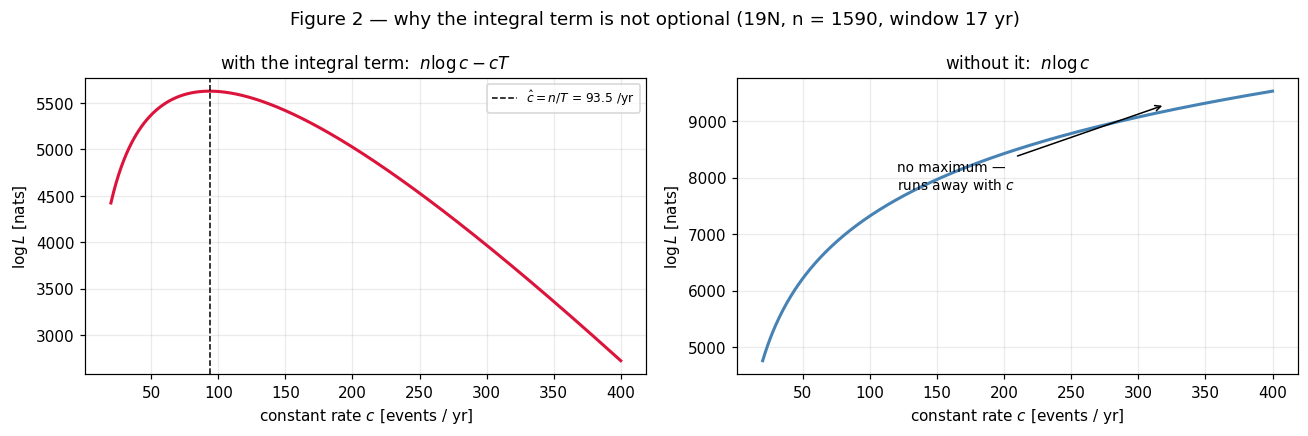

In [24]:
# Given: Figure 2 — the integral term, present and absent.
c_grid = np.linspace(20.0, 400.0, 400)
ll_with = np.array([n_example * np.log(c) - c * WINDOW_YEARS for c in c_grid])
ll_without = np.array([n_example * np.log(c) for c in c_grid])
c_hat = n_example / WINDOW_YEARS

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(c_grid, ll_with, color="crimson", lw=2)
axes[0].axvline(c_hat, color="k", lw=1.0, ls="--", label=f"$\\hat{{c}} = n/T$ = {c_hat:.1f} /yr")
axes[0].set_title(r"with the integral term:  $n\log c - cT$")
axes[0].legend(fontsize=8)
axes[1].plot(c_grid, ll_without, color="steelblue", lw=2)
axes[1].annotate("no maximum —\nruns away with $c$", xy=(320, ll_without[-60]),
                 xytext=(120, ll_without[-60] - 1500), fontsize=9,
                 arrowprops=dict(arrowstyle="->", lw=1.0))
axes[1].set_title(r"without it:  $n\log c$")
for ax in axes:
    ax.set_xlabel("constant rate $c$ [events / yr]")
    ax.set_ylabel(r"$\log L$ [nats]")
fig.suptitle(f"Figure 2 — why the integral term is not optional ({example}, "
             f"n = {n_example}, window {WINDOW_YEARS:.0f} yr)")
plt.tight_layout()
plt.show()

In [25]:
# Given: the constant-rate baseline, every development hemicycle, in the week's units.
baseline_rows = []
for label in DEV_HEMICYCLES:
    events = EVENTS[label]
    c_fit = len(events) / WINDOW_YEARS
    ll = log_likelihood(events, lambda s: np.full_like(np.asarray(s, float), c_fit))
    baseline_rows.append(dict(hemicycle=label, n=len(events), c_hat=c_fit, nll=-ll))
baseline = pd.DataFrame(baseline_rows).set_index("hemicycle")
BASELINE_NLL_PER_YEAR = baseline["nll"].sum() / (len(DEV_HEMICYCLES) * WINDOW_YEARS)

print(baseline.to_string(float_format=lambda v: f"{v:10.2f}"))
print(f"\nconstant-rate baseline: {BASELINE_NLL_PER_YEAR:.2f} nats per hemicycle-year")
print("(negative, and that is fine — see the text above. Lower is better.)")

              n      c_hat        nll
hemicycle                            
12N         525      30.88   -1275.85
12S         664      39.06   -1769.61
13N         716      42.12   -1962.17
13S         850      50.00   -2475.22
14N         613      36.06   -1584.70
14S         640      37.65   -1682.08
15N         794      46.71   -2258.03
15S         697      41.00   -1891.36
17N        1000      58.82   -3074.54
17S        1021      60.06   -3160.33
18N        1138      66.94   -3645.94
18S        1133      66.65   -3624.93
19N        1590      93.53   -5625.86
19S        1121      65.94   -3574.60
21N        1024      60.24   -3172.62
21S        1050      61.76   -3279.50
23N         928      54.59   -2783.83
23S        1107      65.12   -3516.05

constant-rate baseline: -164.57 nats per hemicycle-year
(negative, and that is fine — see the text above. Lower is better.)


### Dialogue for Section 2 — the two terms, and what they are worth

Nothing to write here. The block below steers the conversation you have with your tutor before you
implement Task 10.

```text
TUTOR DIRECTIVE — Section 2. Work this before the student implements Task 10.

Material: the student is about to implement log L = sum_i log lambda(s_i) - integral of lambda over a
fixed observation window, with the integral done by the trapezoid rule on a fixed mesh. Nothing has been
computed yet. Figure 1 shows the event times they will fit; Figure 2 will show the log-likelihood of a
constant-rate model with and without the integral term.

Hold the student to the destinations below before they write any code. Reach them in whatever order the
conversation takes, and reach them through the student's own reformulation rather than your exposition.

1. The two terms. Get the student to say what each term rewards, separately. Then ask what a model
   maximizing only the first term would look like, and require a description of the shape of that
   model rather than the word "overfitting".
2. What the integral is the log-probability *of*. Do not supply this. The student has the Poisson
   distribution from Week 01; push them to connect the probability of zero events in an interval to the
   second term. If they get stuck, bridge via a single interval with constant rate before returning to
   the integral.
3. The window. The likelihood is defined relative to a stated observation window, and the notebook fixes
   one window for all 18 hemicycles. Ask the student what happens to the score if the window is widened
   by five years of time in which nothing could possibly have happened — both to the integral term and
   to a per-year average. Require them to say which part of the number moved and why.
4. The change of units. Last week's score was nats per event; this week's is nats per hemicycle-year.
   The student has their Week 01 HANDOFF, where the Section 2 dialogue established that a per-event
   score cannot reward a model for getting the number of events right. Ask them to say what a per-time
   score can reward that a per-event score cannot, and then why this week's number comes out negative
   when last week's was positive. The second half is harder; bridge towards the units of lambda rather
   than stating the answer.

`log-likelihood`, `intensity function` and `inhomogeneous Poisson process` are the targets least likely
to have been deployed by this point; prefer them when you choose an anchor.
```

---
## 3 · A shape for λ(s)

Figure 1 tells us what λ(s) has to do: stay at zero, turn on, rise over a couple of years, peak near
`s` = 0, and decay over five or six. A gamma-like curve does all of that with three shape parameters and
a scale:

```
λ(s) = a · (s − s₀)^(k−1) · exp(−(s − s₀) / θ)      for s > s₀,   and 0 otherwise
```

- `s₀` is the **onset**: the time in `s` at which emergence in this wing becomes possible at all. It is a
  fitted quantity, anchored in `s` like everything else in this program — never at a cycle minimum, and
  never as a fraction of a cycle's length.
- `k > 1` controls how sharply the rate rises after the onset. The curve leaves zero like (s − s₀)^(k−1),
  so larger `k` means a flatter start and a more symmetric bump.
- `θ` is the decay timescale of the exponential tail, in years.
- `a > 0` is a pure scale with no effect on the shape. The peak sits at s₀ + (k−1)·θ.

This is the same functional form as a gamma probability density, but it is *not* a probability density
here: it does not integrate to 1, and it must not. Its integral over the window is the expected number of
events, which is exactly the information 1.0's normalized latitude distribution threw away.

### Making every fitted quantity unconstrained

Three of these four parameters are not free to take any real value: `a` and `θ` must be positive, and `k`
must exceed 1. An optimizer that does not know that will happily step to θ = −0.3 and return nonsense. We
could hand the optimizer bounds, but it is cleaner and more robust to change variables so that *every*
number the optimizer sees can be any real value at all — an **unconstrained parameterization**. We fit a
vector `q` of four unconstrained reals and map it to the parameters:

```
a  = exp(q₀)                            positive for any q₀
θ  = exp(q₁)                            positive for any q₁
k  = 1 + exp(q₂)                        greater than 1 for any q₂
s₀ = s_a + (s_first − s_a) · σ(q₃)      strictly between s_a and the first event, for any q₃
```

where σ is the logistic function 1/(1 + e^(−x)) and `s_first` is the hemicycle's earliest event.

The last line carries two requirements at once, and the second one is easy to miss. Obviously the onset
must be *before* the first event, or the model calls an observed event impossible and the likelihood is
−∞. Less obviously it must be *after* the start of the observation window: if s₀ were below s_a, part of
the model's rate would lie outside the window, the integral term would not account for it, and we would be
fitting a model whose predictions we never checked against anything. Squeezing s₀ between the two with a
logistic enforces both, with no bounds and no penalty terms.

Keep in mind what we have *not* claimed. That a parameterization is well behaved for the optimizer says
nothing about whether the data can determine the parameters. Section 7 is about that, and the answer is
more interesting than this section lets on.

### A note on the integral

This particular shape does happen to have a closed-form integral, in terms of the regularized incomplete
gamma function. We deliberately do not use it. The model this program is actually building —
`Λ = c · softplus(B − B_crit)^α` in Phase B — has no analytic integral, which is precisely why Scoreboard 1
is defined on a fixed quadrature mesh. A verification technique that stops working in Week 5 is not worth
learning now, so instead we establish that the mesh is good enough by a method that always works:
*refine it and watch.*

In [26]:
# Given: the formula itself. Task 11 is about the parameterization, not about retyping this.
def gamma_rate_parts(s, a, theta, k, s_onset):
    """lambda(s) = a (s - s0)^(k-1) exp(-(s - s0)/theta) for s > s0, else 0. Returns an array."""
    x = np.atleast_1d(np.asarray(s, dtype=float)) - s_onset
    out = np.zeros_like(x)
    live = x > 0.0
    with np.errstate(over="ignore", invalid="ignore"):
        out[live] = a * x[live] ** (k - 1.0) * np.exp(-x[live] / theta)
    return out

In [ ]:
#raise NotImplementedError("Task 11: The unconstrained parameterization of the gamma rate")
# Reference workflow:
#   1. Write `unpack(q, s_first)`: read the four components of `q` and apply the four maps in the text —
#      exponentials for `a` and `theta`, one-plus-exponential for `k`, and for the onset, the window start
#      plus the distance to the first event times the logistic of the fourth component.
#   2. Return them in the order (a, theta, k, s_onset), as plain floats.
#   3. Write `gamma_rate(s, q, s_first)` as a one-liner: unpack, then hand the four parameters to the
#      given `gamma_rate_parts`.
#   4. Sanity-check your logistic by hand before moving on: q3 = 0 should put the onset exactly halfway
#      between the window start and the first event, and large positive q3 should put it just below the
#      first event.

In [29]:
def unpack(q, s_first):
    a       = float(np.exp(q[0]))
    theta   = float(np.exp(q[1]))
    k       = float(1.0 + np.exp(q[2]))
    logistic = 1.0 / (1.0 + np.exp(-q[3]))
    s_onset = float(S_A + (s_first - S_A) * logistic)
# 2
    return a, theta, k, s_onset
# 3
def gamma_rate(s, q, s_first):
    return gamma_rate_parts(s, *unpack(q, s_first))

In [30]:
# Given: check the parameterization does what the text claims.
q_demo = np.array([0.0, np.log(0.65), np.log(10.0 - 1.0), 0.0])
s_first_demo = -4.0

for z in (-4.0, 0.0, 4.0):
    q_try = q_demo.copy()
    q_try[3] = z
    a, theta, k, s_onset = unpack(q_try, s_first_demo)
    print(f"q3 = {z:+.1f}  ->  s_onset = {s_onset:+.3f}  (window starts {S_A:+.1f}, "
          f"first event {s_first_demo:+.1f})")
_, theta_demo, k_demo, onset_demo = unpack(q_demo, s_first_demo)
print(f"\na > 0 and theta > 0 for every real q: theta = {theta_demo:.3f}, k = {k_demo:.3f}")
assert S_A < onset_demo < s_first_demo

q3 = -4.0  ->  s_onset = -5.964  (window starts -6.0, first event -4.0)
q3 = +0.0  ->  s_onset = -5.000  (window starts -6.0, first event -4.0)
q3 = +4.0  ->  s_onset = -4.036  (window starts -6.0, first event -4.0)

a > 0 and theta > 0 for every real q: theta = 0.650, k = 10.000


In [31]:
# Given: does the mesh resolve the integral? Halve the spacing and watch the answer stop moving.
# The trapezoid rule is second order, so each halving should shrink the change by a factor of 4. We never
# compare against an exact answer — that is the point.
a_unit, theta_demo, k_demo, onset_demo = unpack(q_demo, s_first_demo)
TARGET_COUNT = 1000.0
a_demo = TARGET_COUNT / trapezoid(
    gamma_rate_parts(S_MESH, 1.0, theta_demo, k_demo, onset_demo), S_MESH)

refine_rows, previous_change, previous_value = [], None, None
for n_nodes in (26, 51, 101, 201, 401, 801, 1601, 3201, 6401):
    mesh = np.linspace(S_A, S_B, n_nodes)
    value = float(trapezoid(gamma_rate_parts(mesh, a_demo, theta_demo, k_demo, onset_demo), mesh))
    change = abs(value - previous_value) if previous_value is not None else np.nan
    ratio = previous_change / change if (previous_change and np.isfinite(change) and change > 0) else np.nan
    refine_rows.append(dict(nodes=n_nodes, spacing_days=(S_B - S_A) / (n_nodes - 1) / ONE_DAY,
                            integral=value, change=change, ratio=ratio))
    previous_change, previous_value = change, value

refinement = pd.DataFrame(refine_rows)
print(refinement.to_string(index=False, float_format=lambda v: f"{v:12.6g}"))

settled = refinement.dropna(subset=["ratio"])
print(f"\nhalving ratio over the refined half of the table: "
      f"{settled['ratio'].iloc[-4:].min():.2f} to {settled['ratio'].iloc[-4:].max():.2f} "
      f"(second order predicts 4)")
print(f"at our {N_MESH}-node mesh the integral is still moving by about "
      f"{refinement.loc[refinement['nodes'] == 3201, 'change'].iloc[0]:.1e} events, "
      f"against {TARGET_COUNT:.0f} expected -> the mesh is not our problem")
assert 3.5 < settled["ratio"].iloc[-4:].min() and settled["ratio"].iloc[-4:].max() < 4.5, \
    "the trapezoid rule is not converging at second order — check gamma_rate_parts"

 nodes  spacing_days     integral       change        ratio
    26        248.37      999.989          NaN          NaN
    51       124.185      999.997     0.008039          NaN
   101       62.0925      999.999    0.0020201       3.9795
   201       31.0463         1000  0.000505792      3.99395
   401       15.5231         1000  0.000126496      3.99848
   801       7.76156         1000   3.1627e-05      3.99962
  1601       3.88078         1000  7.90694e-06       3.9999
  3201       1.94039         1000  1.97675e-06      3.99998
  6401      0.970195         1000  4.94187e-07      3.99999

halving ratio over the refined half of the table: 4.00 to 4.00 (second order predicts 4)
at our 4001-node mesh the integral is still moving by about 2.0e-06 events, against 1000 expected -> the mesh is not our problem


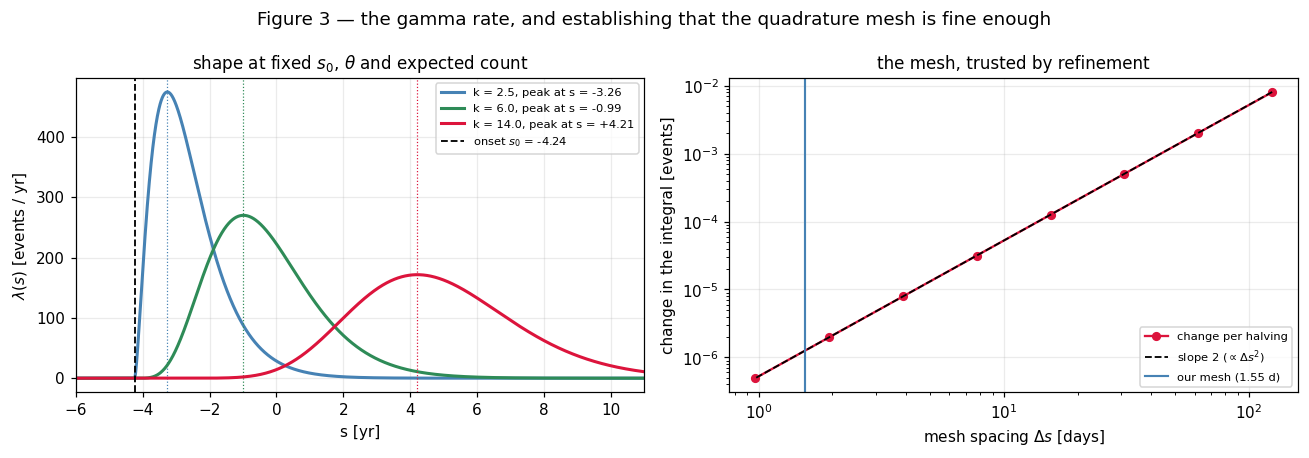

In [32]:
# Given: Figure 3 — the shape, and the convergence.
fig = plt.figure(figsize=(12, 4.2))
ax = fig.add_subplot(1, 2, 1)
for k_show, colour in zip((2.5, 6.0, 14.0), ("steelblue", "seagreen", "crimson")):
    q_show = np.array([0.0, np.log(0.65), np.log(k_show - 1.0), 2.0])
    a_show, th_show, kk, onset_show = unpack(q_show, s_first_demo)
    scale = TARGET_COUNT / trapezoid(
        gamma_rate_parts(S_MESH, 1.0, th_show, kk, onset_show), S_MESH)
    ax.plot(S_MESH, gamma_rate_parts(S_MESH, scale, th_show, kk, onset_show),
            color=colour, lw=2, label=f"k = {kk:.1f}, peak at s = {onset_show + (kk - 1) * th_show:+.2f}")
    ax.axvline(onset_show + (kk - 1) * th_show, color=colour, lw=0.8, ls=":")
ax.axvline(onset_show, color="k", lw=1.2, ls="--", label=f"onset $s_0$ = {onset_show:+.2f}")
ax.set_xlabel("s [yr]")
ax.set_ylabel(r"$\lambda(s)$ [events / yr]")
ax.set_title(r"shape at fixed $s_0$, $\theta$ and expected count")
ax.set_xlim(S_A, S_B)
ax.legend(fontsize=7.5)

ax2 = fig.add_subplot(1, 2, 2)
ok = refinement.dropna(subset=["change"])
ax2.loglog(ok["spacing_days"], ok["change"], "o-", color="crimson", ms=5, label="change per halving")
reference = ok["change"].iloc[-1] * (ok["spacing_days"] / ok["spacing_days"].iloc[-1]) ** 2
ax2.loglog(ok["spacing_days"], reference, "k--", lw=1.2, label=r"slope 2 ($\propto \Delta s^2$)")
ax2.axvline(MESH_STEP_DAYS, color="steelblue", lw=1.4,
            label=f"our mesh ({MESH_STEP_DAYS:.2f} d)")
ax2.set_xlabel(r"mesh spacing $\Delta s$ [days]")
ax2.set_ylabel("change in the integral [events]")
ax2.set_title("the mesh, trusted by refinement")
ax2.legend(fontsize=7.5)
fig.suptitle("Figure 3 — the gamma rate, and establishing that the quadrature mesh is fine enough")
plt.tight_layout()
plt.show()

---
## 4 · One fit per hemicycle

Now we maximize. For one hemicycle, the **maximum likelihood estimate** of the rate is the parameter
vector that makes the log-likelihood of that hemicycle's observed event times as large as possible. We
find it by handing the *negative* log-likelihood to `scipy.optimize.minimize`, since optimizers minimize
by convention.

Three practical points, all of which matter more than they look.

*Fits are per hemicycle and independent this week.* Eighteen separate four-parameter fits, nothing shared.
That is deliberately the wrong thing to do — 18 wings almost certainly share something about their shape,
and a wing with 525 events is being asked to determine four parameters on its own. Week 3 pools them.
Doing it the naive way first is what makes the case for pooling an argument rather than an assertion.

*Nelder–Mead, not a gradient method.* Our likelihood is cheap to evaluate and we have not written down its
derivatives, so a derivative-free simplex method is the right tool. It is also robust to the flat regions
we are about to discover. Phase B swaps this for gradient descent, because by then the derivatives come
for free from autodifferentiation.

*Multiple starting points.* A likelihood surface can have more than one local maximum, and the honest way
to deal with that is to start from several places and keep the best. We use six starts per hemicycle. If
different starts landed at noticeably different likelihoods we would have to say so; they do not, but the
reason is not that the surface is simple, as Section 7 shows.

In [ ]:
#raise NotImplementedError("Task 12: Fit one hemicycle by maximum likelihood")
# Reference workflow:
#   1. Sort the event times and keep the first one — the parameterization needs it, and nothing may assume
#      the table arrived sorted.
#   2. Define the objective: minus the Task 10 log-likelihood of these events under `gamma_rate` with the
#      trial parameters. Return a large finite number rather than +inf when the likelihood is -inf, so the
#      optimizer can step away from a bad region instead of stalling in it.
#   3. Loop over a few starting values of `k` and of the onset position. For each, pick a starting `theta`
#      that puts the peak within a year or two, then choose the starting `a` so that the model's expected
#      count already equals the observed count — integrate the rate with a = 1 and divide.
#   4. Run `minimize` with `method="Nelder-Mead"`, then run it again starting from its own answer. Keep
#      whichever of the six starts reached the lowest objective, and return its parameter vector.
#   Name it `fit_hemicycle(event_s, s_mesh=S_MESH)` and return the pair `(q_hat, s_first)`. Later cells
#   call it by that name and unpack both values, including on simulated data in Task 14.

In [34]:
def fit_hemicycle(event_s, s_mesh=S_MESH):
# 1
    events = np.sort(np.asarray(event_s, dtype=float))
    s_first = events[0]
    n = len(events)
# 2
    def objective(q):
        ll = log_likelihood(events, lambda s: gamma_rate(s, q, s_first), s_mesh)
        return -ll if np.isfinite(ll) else 1e12
# 3
    best = None
    for k0 in (2.0, 5.0):
        for frac in (0.2, 0.5, 0.8):
            onset0 = S_A + (s_first - S_A) * frac
            theta0 = 1.5 / (k0 - 1.0)
            unit = trapezoid(gamma_rate_parts(s_mesh, 1.0, theta0, k0, onset0), s_mesh)
            a0 = n / unit
            q0 = np.array([np.log(a0),
                           np.log(theta0),
                           np.log(k0 - 1.0),
                           np.log(frac / (1.0 - frac))])
# 4
            res = minimize(objective, q0, method="Nelder-Mead")
            res = minimize(objective, res.x, method="Nelder-Mead")
            if best is None or res.fun < best.fun:
                best = res

    return best.x, s_first

In [35]:
# Given: fit all 18 development hemicycles. About 25 seconds.
FITS = {}
fit_rows = []
for label in DEV_HEMICYCLES:
    events = EVENTS[label]
    q_hat, s_first = fit_hemicycle(events)
    FITS[label] = (q_hat, s_first)

    a, theta, k, s_onset = unpack(q_hat, s_first)
    expected = float(trapezoid(gamma_rate(S_MESH, q_hat, s_first), S_MESH))
    nll = -log_likelihood(events, lambda s: gamma_rate(s, q_hat, s_first))
    fit_rows.append(dict(hemicycle=label, n=len(events), k=k, theta=theta, s_onset=s_onset,
                         s_peak=s_onset + (k - 1.0) * theta, width=np.sqrt(k) * theta,
                         expected=expected, nll=nll))

fits = pd.DataFrame(fit_rows).set_index("hemicycle")
print(fits.to_string(float_format=lambda v: f"{v:10.4f}"))

GAMMA_NLL_PER_YEAR = fits["nll"].sum() / (len(DEV_HEMICYCLES) * WINDOW_YEARS)
print(f"\ngamma rate       : {GAMMA_NLL_PER_YEAR:.2f} nats per hemicycle-year")
print(f"constant baseline: {BASELINE_NLL_PER_YEAR:.2f} nats per hemicycle-year")
print(f"improvement      : {BASELINE_NLL_PER_YEAR - GAMMA_NLL_PER_YEAR:.2f} nats per hemicycle-year")
print("(in sample — every event was used to fit the model scoring it. Week 3 adds held-out scoring.)")

              n          k      theta    s_onset     s_peak      width   expected        nll
hemicycle                                                                                   
12N         525    10.9605     0.6075    -6.0000     0.0514     2.0113   525.0000 -1668.2058
12S         664    13.7718     0.5844    -6.0000     1.4632     2.1685   664.0000 -2213.8359
13N         716     3.8087     1.1892    -3.0361     0.3041     2.3209   715.9995 -2448.3524
13S         850     8.2054     0.7896    -5.2604     0.4289     2.2618   850.0004 -3023.2388
14N         613    17.1625     0.4725    -5.7700     1.8663     1.9573   613.0000 -2053.2030
14S         640    10.5842     0.7354    -6.0000     1.0485     2.3926   640.0000 -2054.9195
15N         794     8.3732     0.7192    -4.3603     0.9421     2.0810   793.9999 -2834.4493
15S         697    12.4007     0.5616    -6.0000     0.4027     1.9777   697.0000 -2421.4452
17N        1000     6.7692     0.8118    -4.7449    -0.0616     2.1121

In [36]:
# Given: an independent check on every fit, which needs no closed form and no reference answer.
# At a maximum of the likelihood the fitted rate's integral over the window must equal the observed count.
# Reason: `a` is a free multiplicative scale, so d(log L)/d(log a) = n - integral, and that is zero at the
# maximum. Any rate model with a free scale has to satisfy this, so the check carries into Phase B.
identity_error = (fits["expected"] - fits["n"]).abs()
print(f"max |expected count - observed count| over 18 fits: {identity_error.max():.2e} events")
assert identity_error.max() < 1e-2, \
    "a fit does not satisfy the maximum-likelihood identity — the optimizer did not converge"
print("every fit satisfies the identity: the optimizer really is at a maximum.")

max |expected count - observed count| over 18 fits: 1.19e-03 events
every fit satisfies the identity: the optimizer really is at a maximum.


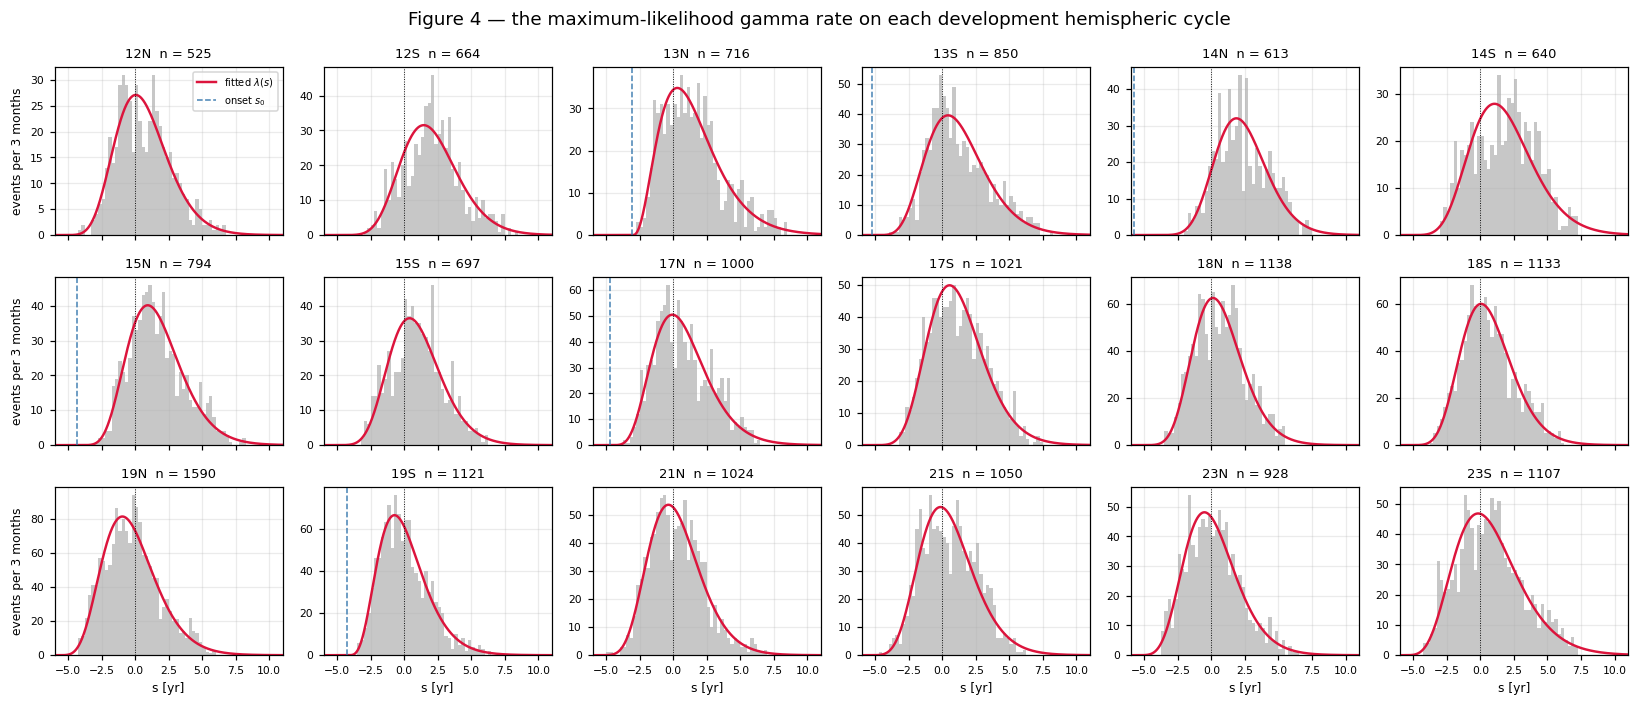

In [37]:
# Given: Figure 4 — the fits over the data.
fig, axes = plt.subplots(3, 6, figsize=(15, 6.5), sharex=True)
bin_width = 0.25

for ax, label in zip(axes.ravel(), DEV_HEMICYCLES):
    q_hat, s_first = FITS[label]
    ax.hist(EVENTS[label], bins=np.arange(S_A, S_B + bin_width, bin_width),
            color="0.78", edgecolor="none")
    ax.plot(S_MESH, gamma_rate(S_MESH, q_hat, s_first) * bin_width, color="crimson", lw=1.6)
    _, _, k, s_onset = unpack(q_hat, s_first)
    ax.axvline(s_onset, color="steelblue", lw=1.0, ls="--")
    ax.axvline(0.0, color="k", lw=0.6, ls=":")
    ax.set_title(f"{label}  n = {len(EVENTS[label])}", fontsize=8.5)
    ax.tick_params(labelsize=7)
    ax.set_xlim(S_A, S_B)
for ax in axes[-1, :]:
    ax.set_xlabel("s [yr]", fontsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel(f"events per {bin_width * 12:.0f} months", fontsize=8)
axes[0, 0].plot([], [], color="crimson", lw=1.6, label=r"fitted $\lambda(s)$")
axes[0, 0].axvline(np.nan, color="steelblue", lw=1.0, ls="--", label=r"onset $s_0$")
axes[0, 0].legend(fontsize=6.5, loc="upper right")
fig.suptitle("Figure 4 — the maximum-likelihood gamma rate on each development hemispheric cycle")
plt.tight_layout()
plt.show()

The curves follow the histograms well: the rise, the peak and the decay are all in roughly the right
places, and the model gains about 39 nats per hemicycle-year on the constant-rate baseline — which is
about 0.72 nats per event, a large margin for four parameters. The dashed blue line in each panel is the
fitted onset, and it is doing something odd: in most panels it sits hard against the left edge of the
window. Hold on to that; Section 7 is about what it means.

Two things we have *not* established. The fits look good, but "looks good" was not an acceptable answer
in Week 1 and is not one now: Section 6 builds a real goodness-of-fit test. And before trusting any number
a fitter produces, we have to know the fitter works — which is the next section, and which is a different
question from whether the model fits the Sun.

---
## 5 · Verify the fitter, then break it on purpose

Week 1 established a habit: before measuring something with a new instrument, measure something whose
answer you already know. There we simulated a homogeneous Poisson process and checked that the Fano
factor came back as 1 — and it caught two real bugs that only showed at wide windows.

The same discipline applies here, and it is more important, because a maximum-likelihood fit will return a
confident-looking answer no matter what is wrong with it. So we need a way to generate data from a rate we
chose ourselves, fit it, and see whether the fit comes back to where we started.

### Simulating an inhomogeneous Poisson process by thinning

Week 1's simulator only handled a constant rate: draw the number of events from a Poisson distribution,
then scatter them uniformly. For a varying rate there is a trick called **thinning**, and it works by
starting from the easy case and throwing events away:

1. Pick a constant rate λ_max that is at least as large as λ(s) everywhere in the window.
2. Simulate a *constant*-rate process at λ_max. Call those the proposals.
3. Keep each proposal at time s independently, with probability λ(s) / λ_max. Discard the rest.

What survives is an inhomogeneous Poisson process with rate exactly λ(s). The reason is the independence
property: in any small interval the proposals arrive at rate λ_max and each survives with probability
λ(s)/λ_max independently of everything else, so survivors arrive at rate λ_max · λ(s)/λ_max = λ(s) — and
because every decision is independent, the result is still Poisson. Where λ is small, almost everything is
discarded; near the peak, almost nothing is.

The one requirement is that λ_max really does bound λ. For our gamma rate we can compute the bound
exactly instead of guessing: the peak is at s₀ + (k−1)·θ, so λ there is the maximum.

In [ ]:
#raise NotImplementedError("Task 13: Simulate a varying rate by thinning a constant one")
# Reference workflow:
#   1. Simulate the constant-rate proposal process exactly as in Week 1: draw the number of proposals from
#      a Poisson distribution with mean `rate_max` times the window length, then place them uniformly in
#      the window and sort.
#   2. Compute each proposal's acceptance probability, the model rate at that time divided by `rate_max`.
#      Raise if any of them exceeds 1 — that means the bound is wrong and the simulation would be silently
#      biased, which is far worse than an error.
#   3. Draw one uniform random number per proposal and keep the proposals whose number falls below their
#      acceptance probability.
#   4. Return the survivors, and also the full proposal array and the mask, so the next cell can draw the
#      ones that were discarded.
#   Name it `simulate_by_thinning(rate_fn, rate_max, s_a, s_b, rng)` and return
#   `(kept, proposed, keep_mask)` in that order.

In [38]:
def simulate_by_thinning(rate_fn, rate_max, s_a, s_b, rng):
    window = s_b - s_a
# 1
    n_prop = rng.poisson(rate_max * window)
    proposed = np.sort(rng.uniform(s_a, s_b, size=n_prop))
# 2
    accept_p = np.asarray(rate_fn(proposed), dtype=float) / rate_max
    if np.any(accept_p > 1.0):
        raise ValueError("rate_max is not an upper bound: "
                         f"max acceptance probability = {accept_p.max():.6f} > 1")
# 3
    u = rng.uniform(size=n_prop)
    keep_mask = u < accept_p
# 4
    kept = proposed[keep_mask]
    return kept, proposed, keep_mask

In [39]:
# Given: thin one hemicycle's fitted rate and check the recovered count and shape are plausible.
TRUTH_LABEL = "19N"
q_true, s_first_true = FITS[TRUTH_LABEL]
a_true, theta_true, k_true, onset_true = unpack(q_true, s_first_true)
s_peak_true = onset_true + (k_true - 1.0) * theta_true
RATE_MAX_TRUE = float(gamma_rate_parts(s_peak_true, a_true, theta_true, k_true, onset_true)[0])

assert gamma_rate(S_MESH, q_true, s_first_true).max() <= RATE_MAX_TRUE + 1e-9, \
    "the analytic peak does not bound the rate on the mesh"

demo_rng = np.random.default_rng(SEED + 10)
kept_demo, proposed_demo, keep_demo = simulate_by_thinning(
    lambda s: gamma_rate(s, q_true, s_first_true), RATE_MAX_TRUE, S_A, S_B, demo_rng)

print(f"truth: {TRUTH_LABEL}'s fitted rate · expected count "
      f"{trapezoid(gamma_rate(S_MESH, q_true, s_first_true), S_MESH):.1f}")
print(f"bounding rate      : {RATE_MAX_TRUE:.1f} events/yr at s = {s_peak_true:+.2f}")
print(f"proposals          : {len(proposed_demo):,}")
print(f"kept               : {keep_demo.sum():,}  "
      f"({keep_demo.mean() * 100:.1f}% accepted)")

truth: 19N's fitted rate · expected count 1590.0
bounding rate      : 325.1 events/yr at s = -0.95
proposals          : 5,552
kept               : 1,589  (28.6% accepted)


In [ ]:
#raise NotImplementedError("Task 14: Recover known parameters from simulated data")
# Reference workflow:
#   1. Loop over 20 replicates. Give each its own generator, `np.random.default_rng(SEED + 100 + i)`, so
#      the whole experiment is reproducible and no two replicates share a random stream.
#   2. In each replicate, thin the known rate to produce a fresh set of event times, then fit those times
#      with Task 12's fitter — exactly as if they were a real hemicycle. The fitter must not be told any of
#      the parameters it is supposed to find.
#   3. Record, per replicate, the event count and the recovered k, theta and onset, plus the two derived
#      quantities the next section cares about: the peak position s0 + (k-1) theta and the width sqrt(k)
#      theta.
#   4. Collect the replicates into a DataFrame. This takes about half a minute — 20 more fits.
#   Two names the next cells need: the replicate count must be `N_RECOVERY`, and the DataFrame must be
#   `recovery`, with one column per recorded quantity named exactly `n`, `k`, `theta`, `s_onset`,
#   `s_peak` and `width`.

In [40]:
N_RECOVERY = 20
rows = []
for i in range(N_RECOVERY):
# 1
    rng = np.random.default_rng(SEED + 100 + i)
# 2
    events, _, _ = simulate_by_thinning(
        lambda s: gamma_rate(s, q_true, s_first_true),
        RATE_MAX_TRUE, S_A, S_B, rng)
    q_hat, s_first = fit_hemicycle(events)
# 3
    a, theta, k, s_onset = unpack(q_hat, s_first)
    rows.append(dict(n=len(events), k=k, theta=theta, s_onset=s_onset,
                     s_peak=s_onset + (k - 1.0) * theta,
                     width=np.sqrt(k) * theta))
# 4
recovery = pd.DataFrame(rows)

In [41]:
# Given: did we get the truth back? The right tolerance is the spread across replicates, not a number of
# decimal places: each replicate is a different random realization, so the estimates *should* scatter.
truth = dict(k=k_true, theta=theta_true, s_onset=onset_true,
             s_peak=s_peak_true, width=np.sqrt(k_true) * theta_true,
             n=float(trapezoid(gamma_rate(S_MESH, q_true, s_first_true), S_MESH)))

summary = pd.DataFrame({
    "truth": pd.Series(truth),
    "mean": recovery.mean(),
    "std": recovery.std(ddof=1),
})
summary["bias"] = summary["mean"] - summary["truth"]
summary["bias / std"] = summary["bias"] / summary["std"]
print(summary.loc[["n", "k", "theta", "s_onset", "s_peak", "width"]]
      .to_string(float_format=lambda v: f"{v:10.4f}"))

worst = summary.loc[["k", "theta", "s_peak", "width"], "bias / std"].abs().max()
print(f"\nlargest bias, in units of the replicate-to-replicate spread: {worst:.2f}")
assert worst < 3.0, "the fitter does not recover the parameters it was given — fix it before going on"
print("the fitter recovers every parameter to within a few standard errors. It works.")

             truth       mean        std       bias  bias / std
n        1590.0000  1588.2500    31.8712    -1.7500     -0.0549
k           7.8717     7.3992     0.6128    -0.4725     -0.7711
theta       0.7353     0.7656     0.0467     0.0302      0.6477
s_onset    -6.0000    -5.8550     0.1918     0.1450      0.7558
s_peak     -0.9471    -0.9818     0.0513    -0.0347     -0.6764
width       2.0631     2.0759     0.0486     0.0128      0.2632

largest bias, in units of the replicate-to-replicate spread: 0.77
the fitter recovers every parameter to within a few standard errors. It works.


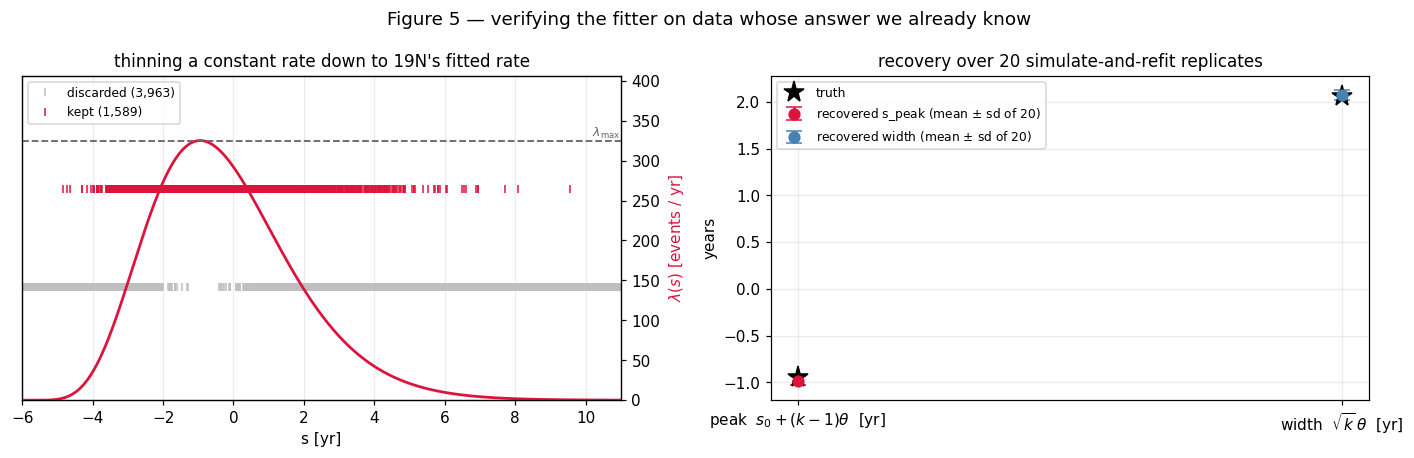

In [42]:
# Given: Figure 5 — thinning, and recovery.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

ax = axes[0]
ax.plot(proposed_demo[~keep_demo], np.full((~keep_demo).sum(), 0.35),
        "|", color="0.75", ms=5, label=f"discarded ({(~keep_demo).sum():,})")
ax.plot(proposed_demo[keep_demo], np.full(keep_demo.sum(), 0.65),
        "|", color="crimson", ms=5, label=f"kept ({keep_demo.sum():,})")
ax2 = ax.twinx()
ax2.plot(S_MESH, gamma_rate(S_MESH, q_true, s_first_true), color="crimson", lw=1.8)
ax2.axhline(RATE_MAX_TRUE, color="0.4", lw=1.2, ls="--")
ax2.text(S_B, RATE_MAX_TRUE, r" $\lambda_{\max}$ ", fontsize=8, color="0.4", ha="right", va="bottom")
ax2.set_ylabel(r"$\lambda(s)$ [events / yr]", color="crimson")
ax2.set_ylim(0, RATE_MAX_TRUE * 1.25)
ax2.grid(False)
ax.set_ylim(0, 1)
ax.set_yticks([])
ax.set_xlim(S_A, S_B)
ax.set_xlabel("s [yr]")
ax.set_title(f"thinning a constant rate down to {TRUTH_LABEL}'s fitted rate")
ax.legend(fontsize=8, loc="upper left")

ax = axes[1]
for i, (name, colour) in enumerate([("s_peak", "crimson"), ("width", "steelblue")]):
    offset = i * 0.0
    ax.errorbar(i, recovery[name].mean(), yerr=recovery[name].std(ddof=1), fmt="o",
                color=colour, ms=7, capsize=5, lw=1.8,
                label=f"recovered {name} (mean $\\pm$ sd of {N_RECOVERY})")
    ax.plot(i, truth[name], "*", color="k", ms=14,
            label="truth" if i == 0 else None)
ax.set_xticks([0, 1])
ax.set_xticklabels([r"peak  $s_0 + (k-1)\theta$  [yr]", r"width  $\sqrt{k}\,\theta$  [yr]"])
ax.set_ylabel("years")
ax.set_title(f"recovery over {N_RECOVERY} simulate-and-refit replicates")
ax.legend(fontsize=8)
fig.suptitle("Figure 5 — verifying the fitter on data whose answer we already know")
plt.tight_layout()
plt.show()

### 5.1 · Two ways to break it

A fitter that passes a recovery test can still be wrong in ways the test cannot see, because the test only
exercises the path where everything is correct. So now we break it deliberately, in the two ways that are
easiest to do by accident, and look at what each failure looks like from the outside. The point is to be
able to recognize the symptom later, when it is not deliberate.

*Drop the integral term.* Section 2 argued this makes the likelihood unbounded. Figure 2 showed it in
one dimension for a constant rate. Here it happens in the real model, and the symptom is specific.

*Integrate over the wrong span.* Suppose you compute Σ log λ over all the events but integrate λ over a
window that is not the one you observed. Nothing raises, nothing diverges, and the fit returns a confident
answer that is simply wrong. In our code the window *is* the mesh, so getting this wrong is one careless
argument away.

In [ ]:
#raise NotImplementedError("Task 15: Break the fitter — drop the integral term")
# Reference workflow:
#   1. Copy the structure of Task 12's fitter, but build the objective from the *first term only*: minus the
#      sum of the logs of the rate at the observed events. Do not evaluate the integral at all.
#   2. Use a single starting point — there is nothing to be careful about, because there is nothing to find.
#   3. Return the parameter vector the optimizer stops at, and the first event time.
#   4. Then, in your own words, write down what you expect `a` and the model's expected event count to be
#      when you print them in the next cell. Commit to the prediction before you run it.
#   Name it `fit_without_integral_term(event_s, s_mesh=S_MESH)`, returning `(q, s_first)` like Task 12.

In [44]:
def fit_without_integral_term(event_s, s_mesh=S_MESH):
# 1
    events = np.sort(np.asarray(event_s, dtype=float))
    s_first = events[0]
    def objective(q):
        rates = gamma_rate(events, q, s_first)
        if not np.all(np.isfinite(rates)) or np.any(rates <= 0):
            return 1e12
        return -np.sum(np.log(rates))

# 2
    q0 = np.array([0.0, 0.0, 0.0, 0.0])
    res = minimize(objective, q0, method="Nelder-Mead")
    res = minimize(objective, res.x, method="Nelder-Mead")
# 3
    return res.x, s_first
# 4 I expect the model's predicted event count to be "infinite" due to the fact that the scale will be increased massively, making it far more difficult to be computer reasonably.
# For 'a' I expect it to be far larger, but probably not "infiinte".

In [45]:
# Given: the symptom.
q_broken, s_first_broken = fit_without_integral_term(EVENTS[TRUTH_LABEL])
a_broken, theta_broken, k_broken, onset_broken = unpack(q_broken, s_first_broken)
with np.errstate(over="ignore"):
    expected_broken = float(trapezoid(gamma_rate(S_MESH, q_broken, s_first_broken), S_MESH))

n_truth_events = len(EVENTS[TRUTH_LABEL])
print(f"correct fit   : a = {a_true:12.4e}   k = {k_true:7.3f}   "
      f"expected count = {truth['n']:9.1f}   (observed {n_truth_events})")
print(f"no integral   : a = {a_broken:12.4e}   k = {k_broken:7.3f}   "
      f"expected count = {expected_broken:9.3e}")

if np.isfinite(expected_broken):
    verdict = (f"{expected_broken / n_truth_events:.1e} times as many events as were observed")
else:
    verdict = ("more events than a float64 can represent — the expected count overflowed to infinity")
print(f"\nThe scale grew by {np.log10(a_broken / a_true):.1f} orders of magnitude and the rise parameter "
      f"ran to {k_broken:.0f};\nthe model now expects {verdict}.")
print("\nThe optimizer did not converge to this — it stopped because every further step produced a")
print("non-finite objective. Nothing raised. Nothing looked wrong until we printed a number.")

assert (not np.isfinite(expected_broken)) or expected_broken > 100 * n_truth_events, \
    "dropping the integral term should make the rate run away — check the broken objective"

correct fit   : a =   4.5907e+00   k =   7.872   expected count =    1590.0   (observed 1590)
no integral   : a =   6.3653e+19   k = 268.391   expected count =       inf

The scale grew by 19.1 orders of magnitude and the rise parameter ran to 268;
the model now expects more events than a float64 can represent — the expected count overflowed to infinity.

The optimizer did not converge to this — it stopped because every further step produced a
non-finite objective. Nothing raised. Nothing looked wrong until we printed a number.


In [46]:
# Given: the second breakage. The window is the mesh, so a wrong window is a wrong mesh argument.
span_rows = []
for name, (lo, hi) in {
    "correct window": (S_A, S_B),
    "tail truncated at s = +6": (S_A, 6.0),
    "start moved to s = -3": (-3.0, S_B),
}.items():
    mesh = np.linspace(lo, hi, N_MESH)
    q_span, s_first_span = fit_hemicycle(EVENTS[TRUTH_LABEL], s_mesh=mesh)
    _, theta_span, k_span, onset_span = unpack(q_span, s_first_span)
    span_rows.append(dict(
        fit=name, integration_span=f"[{lo:+.1f}, {hi:+.1f}]", k=k_span,
        s_peak=onset_span + (k_span - 1.0) * theta_span, width=np.sqrt(k_span) * theta_span,
        count_in_true_window=float(trapezoid(gamma_rate(S_MESH, q_span, s_first_span), S_MESH)),
    ))
    FITS.setdefault("_spans", {})[name] = (q_span, s_first_span)

spans = pd.DataFrame(span_rows).set_index("fit")
print(spans.to_string(float_format=lambda v: f"{v:10.3f}"))
print(f"\nobserved count in {TRUTH_LABEL}: {len(EVENTS[TRUTH_LABEL])}")
print("Moving the start of the integration span forward by three years — three years in which this wing "
      "produced\nvery few events — shifts the fitted peak by well over a year and inflates the implied "
      "event count by about 30%.")

                         integration_span          k     s_peak      width  count_in_true_window
fit                                                                                             
correct window              [-6.0, +11.0]      7.872     -0.947      2.063              1590.000
tail truncated at s = +6     [-6.0, +6.0]      5.718     -1.039      2.200              1609.440
start moved to s = -3       [-3.0, +11.0]      3.909     -2.305      2.511              2061.574

observed count in 19N: 1590
Moving the start of the integration span forward by three years — three years in which this wing produced
very few events — shifts the fitted peak by well over a year and inflates the implied event count by about 30%.


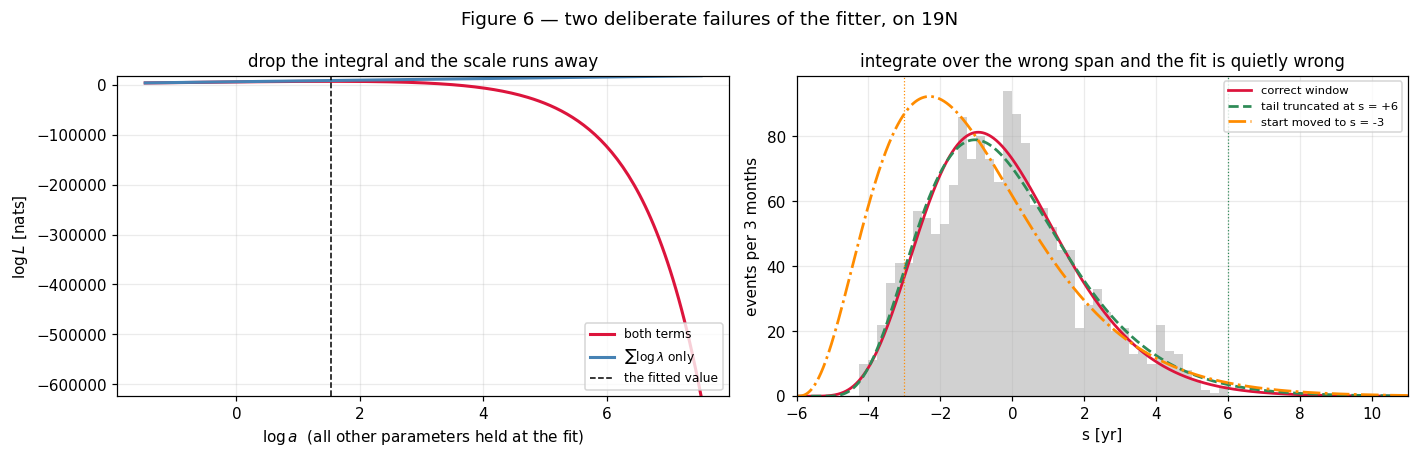

In [47]:
# Given: Figure 6 — both failures.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

ax = axes[0]
log_a_grid = np.linspace(np.log(a_true) - 3.0, np.log(a_true) + 6.0, 200)
events_truth = EVENTS[TRUTH_LABEL]
with_integral, without_integral = [], []
for log_a in log_a_grid:
    q_slice = q_true.copy()
    q_slice[0] = log_a
    rate_at_events = gamma_rate(events_truth, q_slice, s_first_true)
    first_term = float(np.sum(np.log(rate_at_events)))
    with_integral.append(first_term - float(trapezoid(gamma_rate(S_MESH, q_slice, s_first_true), S_MESH)))
    without_integral.append(first_term)
ax.plot(log_a_grid, with_integral, color="crimson", lw=2, label="both terms")
ax.plot(log_a_grid, without_integral, color="steelblue", lw=2, label=r"$\sum \log \lambda$ only")
ax.axvline(np.log(a_true), color="k", lw=1.0, ls="--", label="the fitted value")
ax.set_xlabel(r"$\log a$  (all other parameters held at the fit)")
ax.set_ylabel(r"$\log L$ [nats]")
ax.set_ylim(min(with_integral) - 200, max(without_integral) + 200)
ax.set_title("drop the integral and the scale runs away")
ax.legend(fontsize=8, loc="lower right")

ax = axes[1]
bin_width = 0.25
ax.hist(events_truth, bins=np.arange(S_A, S_B + bin_width, bin_width),
        color="0.82", edgecolor="none")
styles = {"correct window": ("crimson", "-"), "tail truncated at s = +6": ("seagreen", "--"),
          "start moved to s = -3": ("darkorange", "-.")}
for name, (colour, dash) in styles.items():
    q_span, s_first_span = FITS["_spans"][name]
    ax.plot(S_MESH, gamma_rate(S_MESH, q_span, s_first_span) * bin_width,
            color=colour, ls=dash, lw=1.8, label=name)
ax.axvline(-3.0, color="darkorange", lw=0.8, ls=":")
ax.axvline(6.0, color="seagreen", lw=0.8, ls=":")
ax.set_xlim(S_A, S_B)
ax.set_xlabel("s [yr]")
ax.set_ylabel(f"events per {bin_width * 12:.0f} months")
ax.set_title("integrate over the wrong span and the fit is quietly wrong")
ax.legend(fontsize=7.5)
fig.suptitle(f"Figure 6 — two deliberate failures of the fitter, on {TRUTH_LABEL}")
plt.tight_layout()
plt.show()

Two different kinds of wrong, and that is the lesson. The first failure is loud: a number near 10³⁰⁸ is
not a plausible rate, and anyone printing it would notice. The second is quiet — the orange curve in
Figure 6 is a perfectly reasonable-looking rate that happens to peak more than a year away from where the
events are densest, and nothing about the fit itself announces the problem.

What distinguishes them is that the quiet failure still violates the identity from Section 4: its integral
over the *true* window is not the observed count. That check costs one line and catches it.

### Dialogue for Section 5 — verifying a tool, and what verification is worth

Nothing to write here. Work this with your tutor before you implement Tasks 13, 14 and 15.

```text
TUTOR DIRECTIVE — Section 5. Work this before the student implements Tasks 13, 14 and 15.

Material: the student is about to write a simulator for a varying-rate Poisson process by thinning a
constant-rate one, use it to generate data from a rate they chose, refit that data twenty times and
check the parameters come back — and then break the fitter twice on purpose, once by dropping the
integral term from the likelihood and once by integrating over a window that is not the observed one.
None of it has been run.

Work this predictively: the student commits to expectations while no number exists yet. Name
destinations, never outcomes.

1. Require a prediction of what the fitter does when the integral term is dropped, and require the
   mechanism rather than the verdict. "It breaks" is not an answer; ask which parameter moves, in which
   direction, and what stops it. They have Figure 2's one-dimensional version to reason from.
2. Ask what "recovered the parameters" should mean quantitatively, before they see any recovery table.
   Push them away from a number of decimal places and towards a tolerance set by how much the estimate
   scatters from one simulated realization to the next. Make them say where that spread comes from.
3. Ask which of the four parameters they expect to recover well and which poorly, and why. Take their
   answer and keep it: Section 7 revisits exactly this, and the conversation is better if they have
   already committed.
4. Ask what a successful recovery does and does not establish. The simulation draws from the same family
   of shapes the fitter assumes, so require the student to say what is being tested and what is assumed
   away. Bridge towards the distinction between verifying an implementation and testing a model.
5. The quadrature. Ask how they would know a mesh is fine enough when there is no closed-form answer to
   compare against — which is the situation from Week 05 on, since the model this program is building has
   no analytic integral. Bridge towards refinement rather than supplying it, and get them to say what
   they would watch and what they would expect to see.

`thinning`, `quadrature` and `maximum likelihood estimate` are the targets least likely to have been
deployed by this point; prefer them when you choose an anchor.
```

---
## 6 · Time-rescaling: a goodness-of-fit test with no free bandwidth

Figure 4 looked good. "Looked good" is what Week 1 refused to accept, and the reason it refused is worth
repeating: the Fano factor needed a rate model, we supplied one by smoothing, and the sign of the answer
then depended on the bandwidth we chose. We need a test with no knob of that kind.

Here is one, and it is the reason point processes are pleasant to work with. It will give us two things:
a **QQ plot**, which puts the quantiles of one distribution against the quantiles of another so that a
departure shows up as a shape rather than as a number, and the **Kolmogorov–Smirnov statistic**, the
largest vertical distance between two cumulative distribution functions, which compresses that shape into
one number once we know what shape to expect.

### The compensator

Define the **compensator** of the process as the integral of the intensity from the start of the window
up to time `s`:

```
Λ(s) = ∫[s_a, s] λ(u) du
```

It is the model's expected number of events so far — the smooth curve that Week 1's staircase N(s) is
supposed to be following. Where λ is large, Λ climbs steeply; where λ is near zero, Λ is flat.

Now use Λ as a new clock. Replace each event time sᵢ by Λ(sᵢ). The **time-rescaling theorem** says that
if λ is the true intensity of the process, then the transformed times are a realization of a Poisson
process with rate exactly 1 — and therefore the gaps between consecutive transformed times,

```
τᵢ = Λ(sᵢ) − Λ(sᵢ₋₁),      with Λ(s₀) ≡ 0 at the start of the window
```

are independent draws from Exp(1), the exponential distribution with mean 1.

The intuition is that Λ stretches time in exactly the places where the rate is high. If the model says
events should come thick and fast around `s` = 0, then the real time between events there is short, but
the *rescaled* time between them is not — Λ advances quickly there. A correct rate model flattens its own
rate variation out of the data, leaving a process with no structure left to explain. An incorrect one
leaves its errors behind, as departures from Exp(1).

What makes this the right test for us is what it does *not* contain: no bins, no windows, no smoothing
width. Nothing to tune, so nothing that can be tuned until the answer comes out the way we wanted.

### First, a problem we inherited

Week 1 found that about a sixth of all consecutive gaps in this catalog are *exactly zero*: groups first
recorded in the same observation share a timestamp exactly. It also found that every event time is
quantized to a whole day, because that is how often the Sun was catalogued.

Both of those are fatal to a test against Exp(1) if we ignore them. A zero gap in real time gives a zero
rescaled gap, and Exp(1) puts zero probability on that; worse, the day quantization means the rescaled
gaps pile up on a lattice rather than filling a continuum. The test would then reject every model we could
ever write down, for a reason that has nothing to do with the model.

So we have to choose a policy, and say what it assumes. *We jitter each event uniformly inside the day it
was recorded in*, using a seeded generator so the result is reproducible. The justification is that the
catalog genuinely carries no information about when within the day a group was first seen — the recorded
hour is the observatory's reporting time, not a measurement — so a uniform draw inside the day adds no
false information and removes a known artifact. This is undoing a quantization, not fudging a fit.

It is still an assumption, so we report the test both ways and let the difference be visible. Two
alternatives we rejected: collapsing tied events into one discards about a sixth of the data and changes
what the rate means (it would count *observations containing an emergence* rather than emergences);
keeping the ties and reporting the affected fraction leaves the headline test uninterpretable.

In [48]:
# Given: how big is the tie problem, per hemicycle?
tie_rows = []
for label in DEV_HEMICYCLES:
    gaps_days = np.diff(EVENTS[label]) / ONE_DAY
    tie_rows.append(dict(hemicycle=label, n=len(EVENTS[label]),
                         tied_fraction=float((gaps_days < 0.5).mean())))
ties = pd.DataFrame(tie_rows).set_index("hemicycle")
print(f"fraction of consecutive gaps that are exactly zero: "
      f"{ties['tied_fraction'].min():.1%} to {ties['tied_fraction'].max():.1%} "
      f"(median {ties['tied_fraction'].median():.1%})")
print(f"worst: {ties['tied_fraction'].idxmax()} at {ties['tied_fraction'].max():.1%} — "
      f"and it is the hemicycle with the most events, which is no coincidence.")

fraction of consecutive gaps that are exactly zero: 10.3% to 25.3% (median 15.6%)
worst: 19N at 25.3% — and it is the hemicycle with the most events, which is no coincidence.


In [ ]:
#raise NotImplementedError("Task 16: The compensator and the rescaled gaps")
# Reference workflow:
#   1. Sort the event times. If a generator was passed, add a uniform draw on [0, one day] to each event
#      first and re-sort — the jitter can reorder events that shared a timestamp, which is the point.
#   2. Build the compensator on the fixed mesh: evaluate the rate at every node, then accumulate it with
#      `scipy.integrate.cumulative_trapezoid`. That function returns one fewer value than it is given, so
#      prepend a zero — the compensator is zero at the start of the window by definition.
#   3. Get Lambda at each event time by interpolating that cumulative curve (`np.interp`). The mesh is
#      finer than a day, so linear interpolation between nodes costs nothing.
#   4. Return the successive differences, with a zero prepended so the first gap is measured from the start
#      of the window rather than from the first event. Never difference across a hemicycle boundary.
#   Name it `rescaled_gaps(event_s, rate_fn, rng=None, s_mesh=S_MESH)`. Note that it takes a rate
#   *function*, like Task 10 — the next cells pass it both the fitted gamma and a constant rate.

In [49]:
def rescaled_gaps(event_s, rate_fn, rng=None, s_mesh=S_MESH):
# 1
    events = np.sort(np.asarray(event_s, dtype=float))
    if rng is not None:
        events = np.sort(events + rng.uniform(0.0, 1.0 / 365.25, size=len(events)))
# 2
    s_mesh = np.asarray(s_mesh, dtype=float)
    lam_mesh = np.asarray(rate_fn(s_mesh), dtype=float)
    Lambda_mesh = np.concatenate(([0.0], cumulative_trapezoid(lam_mesh, s_mesh)))
# 3
    Lambda_events = np.interp(events, s_mesh, Lambda_mesh)
# 4
    return np.diff(Lambda_events, prepend=0.0)

In [ ]:
#raise NotImplementedError("Task 17: The Kolmogorov-Smirnov statistic against Exp(1)")
# Reference workflow:
#   1. Sort the gaps. The empirical cumulative distribution function is a staircase that steps up by 1/n at
#      each one.
#   2. Evaluate the Exp(1) CDF, 1 - exp(-tau), at each sorted gap.
#   3. The statistic is the largest absolute difference between the two CDFs. Because the empirical one is a
#      staircase, the largest difference can occur on either side of a step, so compare both: the value
#      just after the k-th step (k/n) and just before it ((k-1)/n), and take the biggest discrepancy over
#      all points and both sides.
#   4. Return a single float. Smaller is better; it is a distance between distributions, not a probability.
#   Name it `ks_vs_exp1(gaps)`.

In [50]:
def ks_vs_exp1(gaps):
# 1
    gaps = np.sort(np.asarray(gaps, dtype=float))
    n = len(gaps)
    k = np.arange(1, n + 1)
# 2
    cdf = 1.0 - np.exp(-gaps)
# 3
    d_after  = np.abs(k / n - cdf)
    d_before = np.abs((k - 1) / n - cdf)
    D = max(d_after.max(), d_before.max())
# 4
    return float(D)

In [51]:
# Given: check the statistic against scipy's implementation before using it.
check_rng = np.random.default_rng(SEED + 20)
for n_sample in (200, 2000):
    sample = check_rng.exponential(1.0, n_sample)
    mine = ks_vs_exp1(sample)
    theirs = kstest(sample, "expon").statistic
    print(f"n = {n_sample:5d}   ours {mine:.8f}   scipy {theirs:.8f}   difference {mine - theirs:+.1e}")
assert abs(mine - theirs) < 1e-12, "our KS statistic disagrees with scipy's"

n =   200   ours 0.09142002   scipy 0.09142002   difference +0.0e+00
n =  2000   ours 0.01807165   scipy 0.01807165   difference +0.0e+00


In [52]:
# Given: the test, three ways, on every development hemicycle.
#   - the fitted gamma rate, with the day-jitter policy applied
#   - the same fitted rate with the ties left in, so the artifact is visible
#   - the constant-rate baseline from Section 2, jittered the same way: a deliberately wrong model
jitter_rng = np.random.default_rng(SEED + 30)
POOLED = {"gamma + jitter": [], "gamma, ties kept": [], "constant + jitter": []}
ks_rows = []

for label in DEV_HEMICYCLES:
    events = EVENTS[label]
    q_hat, s_first = FITS[label]
    gamma_fn = lambda s, q=q_hat, sf=s_first: gamma_rate(s, q, sf)
    c_hat = len(events) / WINDOW_YEARS
    constant_fn = lambda s, c=c_hat: np.full_like(np.asarray(s, float), c)

    # The two jittered variants get the same jitter draw, so they see identical event times.
    variants = {
        "gamma + jitter": rescaled_gaps(events, gamma_fn, rng=np.random.default_rng(
            SEED + 1000 + DEV_HEMICYCLES.index(label))),
        "gamma, ties kept": rescaled_gaps(events, gamma_fn),
        "constant + jitter": rescaled_gaps(events, constant_fn, rng=np.random.default_rng(
            SEED + 1000 + DEV_HEMICYCLES.index(label))),
    }
    row = dict(hemicycle=label, n=len(events))
    for name, gaps in variants.items():
        POOLED[name].append(gaps)
        row[name] = ks_vs_exp1(gaps)
        row[name + " p"] = kstest(gaps, "expon").pvalue
    ks_rows.append(row)

ks_table = pd.DataFrame(ks_rows).set_index("hemicycle")
POOLED = {name: np.concatenate(parts) for name, parts in POOLED.items()}

print(ks_table[["n", "gamma + jitter", "gamma, ties kept", "constant + jitter"]]
      .to_string(float_format=lambda v: f"{v:10.4f}"))
print("\nmedian KS statistic:")
for name in POOLED:
    print(f"   {name:20s} {ks_table[name].median():.4f}")
print("\npooled over all 18 hemicycles:")
for name, gaps in POOLED.items():
    print(f"   {name:20s} KS {ks_vs_exp1(gaps):.4f}   mean gap {gaps.mean():.3f} "
          f"(Exp(1) has mean 1)   zero gaps {float((gaps == 0.0).mean()):.1%}")

n_pass = int((ks_table["gamma + jitter p"] > 0.05).sum())
print(f"\nthe fitted gamma rate is not rejected at the 5% level in {n_pass} of "
      f"{len(DEV_HEMICYCLES)} hemicycles")
print(f"the constant rate is rejected in "
      f"{int((ks_table['constant + jitter p'] < 0.05).sum())} of {len(DEV_HEMICYCLES)}")

              n  gamma + jitter  gamma, ties kept  constant + jitter
hemicycle                                                           
12N         525          0.0256            0.1029             0.2883
12S         664          0.0416            0.1370             0.2612
13N         716          0.0207            0.1285             0.2600
13S         850          0.0156            0.1365             0.2443
14N         613          0.0444            0.1126             0.2905
14S         640          0.0771            0.1328             0.2338
15N         794          0.0326            0.1499             0.2815
15S         697          0.0328            0.1248             0.2902
17N        1000          0.0262            0.1690             0.2680
17S        1021          0.0198            0.1655             0.2689
18N        1138          0.0287            0.2039             0.3091
18S        1133          0.0248            0.1959             0.2873
19N        1590          0.0222   

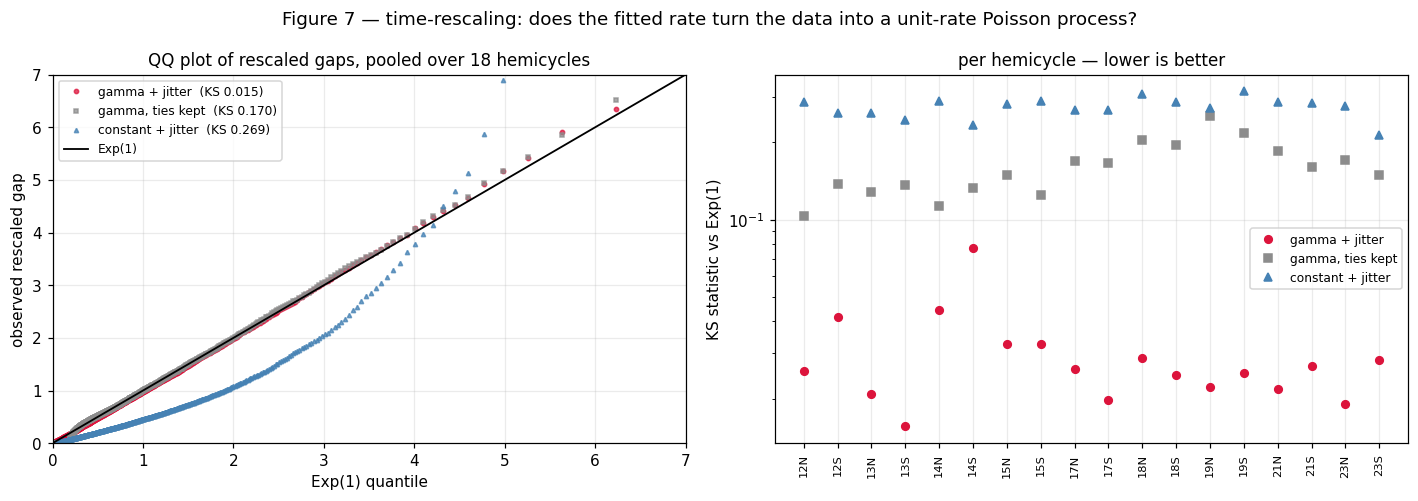

In [53]:
# Given: Figure 7 — the QQ plot, and the per-hemicycle statistic.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
styles = {"gamma + jitter": ("crimson", "o"), "gamma, ties kept": ("0.55", "s"),
          "constant + jitter": ("steelblue", "^")}

ax = axes[0]
for name, (colour, marker) in styles.items():
    observed = np.sort(POOLED[name])
    n = len(observed)
    theoretical = -np.log(1.0 - (np.arange(1, n + 1) - 0.5) / n)   # Exp(1) quantiles
    step = max(1, n // 600)
    ax.plot(theoretical[::step], observed[::step], marker, color=colour, ms=2.8, alpha=0.75,
            label=f"{name}  (KS {ks_vs_exp1(POOLED[name]):.3f})")
limit = 7.0
ax.plot([0, limit], [0, limit], "k-", lw=1.2, label="Exp(1)")
ax.set_xlim(0, limit)
ax.set_ylim(0, limit)
ax.set_xlabel("Exp(1) quantile")
ax.set_ylabel("observed rescaled gap")
ax.set_title("QQ plot of rescaled gaps, pooled over 18 hemicycles")
ax.legend(fontsize=8, loc="upper left")

ax = axes[1]
positions = np.arange(len(DEV_HEMICYCLES))
for name, (colour, marker) in styles.items():
    ax.plot(positions, ks_table[name].to_numpy(), marker, color=colour, ms=5, label=name)
ax.set_xticks(positions)
ax.set_xticklabels(DEV_HEMICYCLES, rotation=90, fontsize=7.5)
ax.set_ylabel("KS statistic vs Exp(1)")
ax.set_yscale("log")
ax.set_title("per hemicycle — lower is better")
ax.legend(fontsize=8)
fig.suptitle("Figure 7 — time-rescaling: does the fitted rate turn the data into a unit-rate "
             "Poisson process?")
plt.tight_layout()
plt.show()

Three things to read off Figure 7, and the middle one is the uncomfortable one.

The fitted gamma rate passes. Its points lie on the diagonal across the whole range, the pooled KS
statistic is 0.015, the mean rescaled gap is 0.99 against the 1 that Exp(1) requires, and 17 of the 18
hemicycles are not rejected at the 5% level. For a four-parameter model of a quantity that varies by a
factor of ten, that is a genuinely good fit — and it is a much stronger statement than Figure 4's eyeball
agreement, because the test had nothing to tune.

The grey points show what the ties do if we ignore them: a flat shelf at the bottom left, where 17% of
the rescaled gaps are exactly zero and Exp(1) says there should be none at all. The median per-hemicycle
KS statistic goes up sixfold, from 0.026 to 0.155, and *every* hemicycle gets rejected. Note what that
would have meant: without a tie policy we would have concluded the model fails badly, and we would have
been diagnosing the catalog's daily sampling as a defect of the Sun.

The constant rate fails two different ways, and the QQ plot separates them. Its points sit *below* the
diagonal through the middle of the range and swing *above* it at the far right: too few mid-sized
rescaled gaps and a handful of enormous ones. That is the signature of a wrong rate *shape* — through the
quiet years at each end of the window the constant model expects events that never come, so the
compensator keeps climbing and the one real gap spanning all that empty time is rescaled into a gap of
hundreds. And its mean rescaled gap is 0.75 rather than 1, which is a wrong rate *level* over the part of
the window where events actually occur. A single plot showing both is why we look at the QQ plot rather
than reading the KS number alone.

### Dialogue for Section 6 — reading a QQ plot

Nothing to write here. Work this with your tutor before you implement Tasks 16 and 17.

```text
TUTOR DIRECTIVE — Section 6. Work this before the student implements Tasks 16 and 17.

Material: the student is about to compute the compensator of their fitted rate, use it to rescale the
event times, and test whether the rescaled gaps are Exp(1) — with a QQ plot and a Kolmogorov-Smirnov
statistic. They will do this for their fitted gamma rate and for a deliberately wrong constant-rate
model. Nothing has been computed yet.

Work this predictively, and do not state any of the outcomes.

1. Require the student to state what the time-rescaling theorem claims, in their own words, and then why
   a correct rate should turn event times into a unit-rate process. Push for the mechanism: what does
   the compensator do to an interval in which the rate is high, and what to one in which it is low? If
   they are stuck, bridge through Week 01's counting process N(s) — the compensator is the smooth curve
   the staircase is supposed to follow.
2. Get a prediction of the shape of the departure the constant-rate model will produce, and in which
   part of the QQ plot it will appear. Do not name the direction and do not confirm theirs. Require them
   to reason from what a constant rate gets wrong about the quiet years at each end of the window.
3. The ties. About a sixth of consecutive gaps in this catalog are exactly zero, and every event time is
   quantized to a whole day. Make the student work out what each of those does to the rescaled gaps and
   to a test against a continuous distribution, before they read the notebook's policy. Then ask them to
   propose a policy of their own and to say what it assumes about the catalog — and separately, what
   would have to be true for their policy to be hiding a real effect rather than removing an artifact.
4. Require a statement of what a passing KS test does not establish. The student has Week 01's argument
   about F(delta) in their HANDOFF: that a statistic can refute a hypothesis without being able to
   confirm it. Ask them to make the same distinction here, and to name something about the process that
   this test is blind to.

`time-rescaling theorem`, `compensator` and `Kolmogorov-Smirnov statistic` are the targets least likely
to have been deployed by this point; prefer them when you choose an anchor.
```

---
## 7 · How much do the shapes vary?

We have 18 independent four-parameter fits, and the obvious next move is to scatter the fitted parameters
against each other and ask how much a wing's shape really varies from cycle to cycle. If the answer is
"hardly at all", then fitting 72 parameters to 18 wings was wasteful and Week 3 should share a shape
between them. If the answer is "a great deal", pooling will do damage.

But look at the `s_onset` column of Section 4's table first. In 11 of the 18 fits it sits at exactly
−6.0000 — the start of the observation window, the lowest value the parameterization allows. A fitted
parameter resting on the edge of its allowed range is a warning, not a result. It means the likelihood
wanted to go further and was stopped by us, and until we understand why, none of the other three
parameters can be interpreted either.

### Profiling the likelihood

The tool for this is the **profile likelihood**. Fix one parameter at a value of your choosing, maximize
the likelihood over all the *others*, and record the best achievable value. Repeat across a range of the
fixed parameter. What you get is a curve showing how much likelihood you give up by insisting on each
value — a slice through the surface that has the other parameters optimized away rather than held still,
which is what makes it the honest slice.

If that curve has a sharp minimum, the data determines the parameter. If it is nearly flat, the data does
not: different values describe the data equally well, so the fitted value is an artifact of where the
optimizer happened to stop, or of a bound we imposed. The property at stake is **identifiability** —
whether the data can distinguish different values of a parameter at all. It belongs to the model and the
data together, not to the optimizer, and a well-behaved unconstrained parameterization, which Section 3
was careful to build, does nothing whatsoever to fix it.

We profile two hemicycles: one whose fitted onset is pinned to the window edge, and one whose onset came
to rest in the interior.

In [ ]:
#raise NotImplementedError("Task 18: Profile the likelihood in the onset")
# Reference workflow:
#   1. Loop over the requested onset values. For each one, the onset is now a *fixed number*, not something
#      the optimizer sees — so the parameter vector has three components, not four.
#   2. Build a three-parameter objective: exponentiate for a and theta, one-plus-exponential for k, hand
#      all four values (the three plus the fixed onset) to the given `gamma_rate_parts`, and take minus the
#      Task 10 log-likelihood. Note that the onset is now outside the optimizer, so there is no logistic.
#   3. Optimize from the same few starting values of k as Task 12, scaling the starting `a` the same way,
#      and keep the best.
#   4. Record, for each onset: the achieved negative log-likelihood and the refitted k, theta, peak
#      position and width. Return them as a DataFrame — the point is to see what moves and what does not.
#   Name it `profile_onset(event_s, onset_values, s_mesh=S_MESH)`, returning one row per onset value with
#   columns named exactly `s_onset`, `nll`, `k`, `theta`, `s_peak` and `width`.

In [54]:
def profile_onset(event_s, onset_values, s_mesh=S_MESH):
    events = np.sort(np.asarray(event_s, dtype=float))
    n = len(events)
    rows = []
# 1
    for onset in onset_values:
# 2
        def objective(p, onset=onset):
            a, theta, k = np.exp(p[0]), np.exp(p[1]), 1.0 + np.exp(p[2])
            ll = log_likelihood(
                events,
                lambda s: gamma_rate_parts(s, a, theta, k, onset),
                s_mesh)
            return -ll if np.isfinite(ll) else 1e12
# 3
        best = None
        for k0 in (2.0, 5.0):
            theta0 = 1.5 / (k0 - 1.0)
            unit = trapezoid(gamma_rate_parts(s_mesh, 1.0, theta0, k0, onset), s_mesh)
            a0 = n / unit
            p0 = np.array([np.log(a0), np.log(theta0), np.log(k0 - 1.0)])

            res = minimize(objective, p0, method="Nelder-Mead")
            res = minimize(objective, res.x, method="Nelder-Mead")

            if best is None or res.fun < best.fun:
                best = res
# 4
        a_hat, theta_hat, k_hat = np.exp(best.x[0]), np.exp(best.x[1]), 1.0 + np.exp(best.x[2])
        rows.append(dict(s_onset=float(onset),
                         nll=float(best.fun),
                         k=float(k_hat),
                         theta=float(theta_hat),
                         s_peak=float(onset + (k_hat - 1.0) * theta_hat),
                         width=float(np.sqrt(k_hat) * theta_hat)))
    return pd.DataFrame(rows)

In [55]:
# Given: profile two hemicycles across the whole range of onsets the parameterization allows.
PROFILE_LABELS = ("19N", "13N")
profiles = {}

for label in PROFILE_LABELS:
    events = EVENTS[label]
    onsets = np.linspace(S_A, events[0] - 0.05, 14)
    profiles[label] = profile_onset(events, onsets)

    best = profiles[label].loc[profiles[label]["nll"].idxmin()]
    table = profiles[label].copy()
    table["delta_nll"] = table["nll"] - table["nll"].min()
    print(f"\n{label}  (n = {len(events)}, first event at s = {events[0]:+.3f}, "
          f"onset may lie in [{S_A:+.1f}, {events[0]:+.2f}])")
    print(table[["s_onset", "delta_nll", "k", "theta", "s_peak", "width"]]
          .to_string(index=False, float_format=lambda v: f"{v:9.4f}"))
    print(f"   NLL range over the whole allowed onset range : {table['delta_nll'].max():.2f} nats "
          f"({table['delta_nll'].max() / len(events):.4f} nats per event)")
    print(f"   k varies by a factor {table['k'].max() / table['k'].min():.2f}, "
          f"theta by {table['theta'].max() / table['theta'].min():.2f}")
    print(f"   but the width varies by only "
          f"{(table['width'].max() / table['width'].min() - 1) * 100:.1f}%, "
          f"and the peak moves {table['s_peak'].max() - table['s_peak'].min():.2f} yr")


19N  (n = 1590, first event at s = -4.231, onset may lie in [-6.0, -4.23])
  s_onset  delta_nll         k     theta    s_peak     width
  -6.0000     0.0000    7.8717    0.7353   -0.9471    2.0631
  -5.8678     0.1648    7.4782    0.7564   -0.9680    2.0683
  -5.7356     0.4383    7.0924    0.7789   -0.9904    2.0743
  -5.6034     0.8460    6.7142    0.8031   -1.0144    2.0809
  -5.4712     1.4207    6.3433    0.8292   -1.0404    2.0885
  -5.3390     2.2062    5.9798    0.8576   -1.0685    2.0971
  -5.2068     3.2611    5.6232    0.8885   -1.0991    2.1069
  -5.0746     4.6677    5.2729    0.9225   -1.1328    2.1183
  -4.9424     6.5444    4.9284    0.9603   -1.1701    2.1318
  -4.8102     9.0722    4.5891    1.0026   -1.2119    2.1477
  -4.6780    12.5467    4.2531    1.0509   -1.2595    2.1672
  -4.5458    17.5091    3.9181    1.1072   -1.3149    2.1917
  -4.4137    25.1625    3.5778    1.1760   -1.3821    2.2244
  -4.2815    39.8522    3.2105    1.2702   -1.4738    2.2758
   NLL ra

In [56]:
# Given: the comparison that settles it. For each quantity, put its spread *across* the 18 hemicycles
# beside the ambiguity *within* a single hemicycle — the range the quantity covers along the ridge, where
# the likelihood is nearly indifferent. A quantity whose between-wing spread is no larger than its
# within-wing ambiguity has not been measured to vary at all.
NATS_TOLERANCE = 4.0        # roughly a 2-sigma likelihood-ratio interval for one parameter

comparison_rows = []
for name in ("k", "theta", "s_peak", "width"):
    row = dict(quantity=name, across_hemicycles=fits[name].max() - fits[name].min())
    for label in PROFILE_LABELS:
        ridge = profiles[label]
        near = ridge[ridge["nll"] - ridge["nll"].min() < NATS_TOLERANCE]
        within = near[name].max() - near[name].min()
        row[f"ridge {label}"] = within
        row[f"ratio {label}"] = row["across_hemicycles"] / within if within else np.inf
    comparison_rows.append(row)
comparison = pd.DataFrame(comparison_rows).set_index("quantity")

print(f"spread across the 18 fits, vs the ambiguity along one hemicycle's ridge "
      f"(within {NATS_TOLERANCE:.0f} nats):")
print(comparison.to_string(float_format=lambda v: f"{v:9.3f}"))
print("\nThe ratio is how many times larger the between-wing variation is than the ambiguity inside one")
print("wing. Small means we cannot claim the quantity varies; large means the variation is real.")
print(f"\n   raw shape parameters (k, theta) : ratios "
      f"{comparison.loc[['k', 'theta'], [f'ratio {h}' for h in PROFILE_LABELS]].to_numpy().min():.1f}"
      f" to {comparison.loc[['k', 'theta'], [f'ratio {h}' for h in PROFILE_LABELS]].to_numpy().max():.1f}")
print(f"   derived peak and width          : ratios "
      f"{comparison.loc[['s_peak', 'width'], [f'ratio {h}' for h in PROFILE_LABELS]].to_numpy().min():.1f}"
      f" to {comparison.loc[['s_peak', 'width'], [f'ratio {h}' for h in PROFILE_LABELS]].to_numpy().max():.1f}")
print(f"\nand separately: the onset is pinned to the window edge in "
      f"{int(((fits['s_onset'] - S_A).abs() < 1e-3).sum())} of {len(DEV_HEMICYCLES)} hemicycles, "
      f"so for those it is not determined by the data at all.")

spread across the 18 fits, vs the ambiguity along one hemicycle's ridge (within 4 nats):
          across_hemicycles  ridge 19N  ratio 19N  ridge 13N  ratio 13N
quantity                                                               
k                    13.354      2.248      5.939      2.308      5.787
theta                 0.717      0.153      4.680      0.314      2.284
s_peak                2.813      0.152     18.502      0.300      9.388
width                 0.678      0.044     15.472      0.099      6.825

The ratio is how many times larger the between-wing variation is than the ambiguity inside one
wing. Small means we cannot claim the quantity varies; large means the variation is real.

   raw shape parameters (k, theta) : ratios 2.3 to 5.9
   derived peak and width          : ratios 6.8 to 18.5

and separately: the onset is pinned to the window edge in 11 of 18 hemicycles, so for those it is not determined by the data at all.


That is the week's real result, and it is more interesting than "the shapes vary by such and such".

The profile is not flat, and it is important to say that accurately rather than reach for the dramatic
version. For 13N the curve has a genuine minimum, in the interior, and the onset is pinned down to a few
tenths of a year. For 19N the curve decreases all the way to the window edge and stops there because we
stopped it — the likelihood was still improving, so that fitted onset is reporting our choice of window,
not the Sun. Eleven of the eighteen hemicycles are in 19N's situation.

What the profile does show is a strong *degeneracy*. Move the onset across the range where the
likelihood is nearly indifferent, and `k` and `θ` follow it by factors of two to four: an earlier onset is
bought back by a flatter rise and a longer decay timescale. The three parameters move together along a
ridge, and the data constrains the ridge far better than it constrains position along it.

The reason is that almost nothing observes the rising edge. Only 19 events in the whole development set —
about one in a thousand — occur before `s` = −4, so the shape of λ in the first years after the onset is
being inferred from a handful of groups.

Now read the comparison table above, which is what turns this from a curiosity into a decision. It asks,
for each quantity, how its spread *across* the 18 hemicycles compares with the ambiguity *within* a
single one. The raw shape parameters come out at ratios of roughly 2 to 6; the derived peak and width at
roughly 7 to 18. So all four do vary between wings by more than the degeneracy allows — we should not
overstate this — but the peak and the width are measured two to three times more sharply relative to how
much they vary, and they are the quantities whose between-wing differences we can actually defend.

The onset is the exception, and it is a clean one: in 11 of 18 hemicycles it is pinned to the window edge,
so for those it carries no information about the Sun whatsoever. Reporting a mean fitted onset across the
18 wings would be reporting our window.

Three quantities survive intact, then: the expected count (pinned exactly by Section 4's identity), the
peak position, and the width. Scattering the raw `k` and `θ` across hemicycles — the obvious thing to do,
and what we set out to do at the top of this section — would have shown a factor-of-four spread in `k`
that is substantially our parameterization rather than the Sun.

This is also the argument for what Week 3 does. If a single hemicycle cannot pin down the rise shape, the
response is not a better optimizer but more data per parameter: share `k` across all 18 wings and let each
keep its own scale and timing. Eighteen wings jointly can determine a rising edge that none of them
determines alone, and the degeneracy is broken by the sharing rather than by a bound we imposed. That is
pooling, and we have just made the case for it from measurement rather than from taste.

In [ ]:
#raise NotImplementedError("Task 19: Physical plausibility — does the fitted rate peak when the area record peaks?")
# Reference workflow:
#   1. Join Section 4's fitted-parameter table to the `amplitudes` table built in Section 1.2, which
#      carries each hemicycle's amplitude `A` and the position in `s` of its 12-month-smoothed area peak.
#   2. Add a column for the difference between the two peak positions: the one fitted to event *times* and
#      the one measured from the *area* record. These are two independent measurements of the same Sun, so
#      disagreement is informative either way.
#   3. Compute three correlations across the 18 hemicycles: fitted peak against area peak, event count
#      against amplitude, and fitted width against amplitude.
#   Four names the next cells need: the joined frame must be `plausibility`, carrying a `peak_difference`
#   column, and the three correlations must be `PEAK_CORRELATION`, `COUNT_AMPLITUDE_CORRELATION` and
#   `WIDTH_AMPLITUDE_CORRELATION`.

In [57]:
AREA_PEAK_COL = "s_peak_area"
# 1
amp = amplitudes
if "hemicycle" in amp.columns:
    amp = amp.set_index("hemicycle")
plausibility = fits.join(amp[["A", AREA_PEAK_COL]], how="inner")
# 2
plausibility["peak_difference"] = plausibility["s_peak"] - plausibility[AREA_PEAK_COL]
# 3
PEAK_CORRELATION            = float(plausibility["s_peak"].corr(plausibility[AREA_PEAK_COL]))
COUNT_AMPLITUDE_CORRELATION = float(plausibility["n"].corr(plausibility["A"]))
WIDTH_AMPLITUDE_CORRELATION = float(plausibility["width"].corr(plausibility["A"]))

In [58]:
# Given: the comparison.
print(plausibility[["n", "A", "s_peak", "s_peak_area", "peak_difference", "width"]]
      .to_string(float_format=lambda v: f"{v:10.3f}"))

difference = plausibility["peak_difference"]
print(f"\nfitted rate peak vs smoothed-area peak, over 18 hemicycles:")
print(f"   correlation            : {PEAK_CORRELATION:+.3f}")
print(f"   mean difference        : {difference.mean():+.3f} yr")
print(f"   scatter (sd)           : {difference.std(ddof=1):.3f} yr")
print(f"   largest disagreement   : {difference.abs().max():.3f} yr "
      f"({difference.abs().idxmax()})")
print(f"\n   event count vs amplitude A : {COUNT_AMPLITUDE_CORRELATION:+.3f}")
print(f"   fitted width vs amplitude A: {WIDTH_AMPLITUDE_CORRELATION:+.3f}")

              n          A     s_peak  s_peak_area  peak_difference      width
hemicycle                                                                     
12N         525      0.079      0.051       -0.218            0.270      2.011
12S         664      0.149      1.463        1.763           -0.300      2.169
13N         716      0.097      0.304       -0.735            1.040      2.321
13S         850      0.145      0.429        0.263            0.166      2.262
14N         613      0.115      1.866        1.659            0.208      1.957
14S         640      0.086      1.049        1.820           -0.771      2.393
15N         794      0.130      0.942        0.950           -0.008      2.081
15S         697      0.116      0.403        0.229            0.174      1.978
17N        1000      0.211     -0.062       -0.513            0.451      2.112
17S        1021      0.161      0.543        1.079           -0.536      2.124
18N        1138      0.193      0.121        1.358  

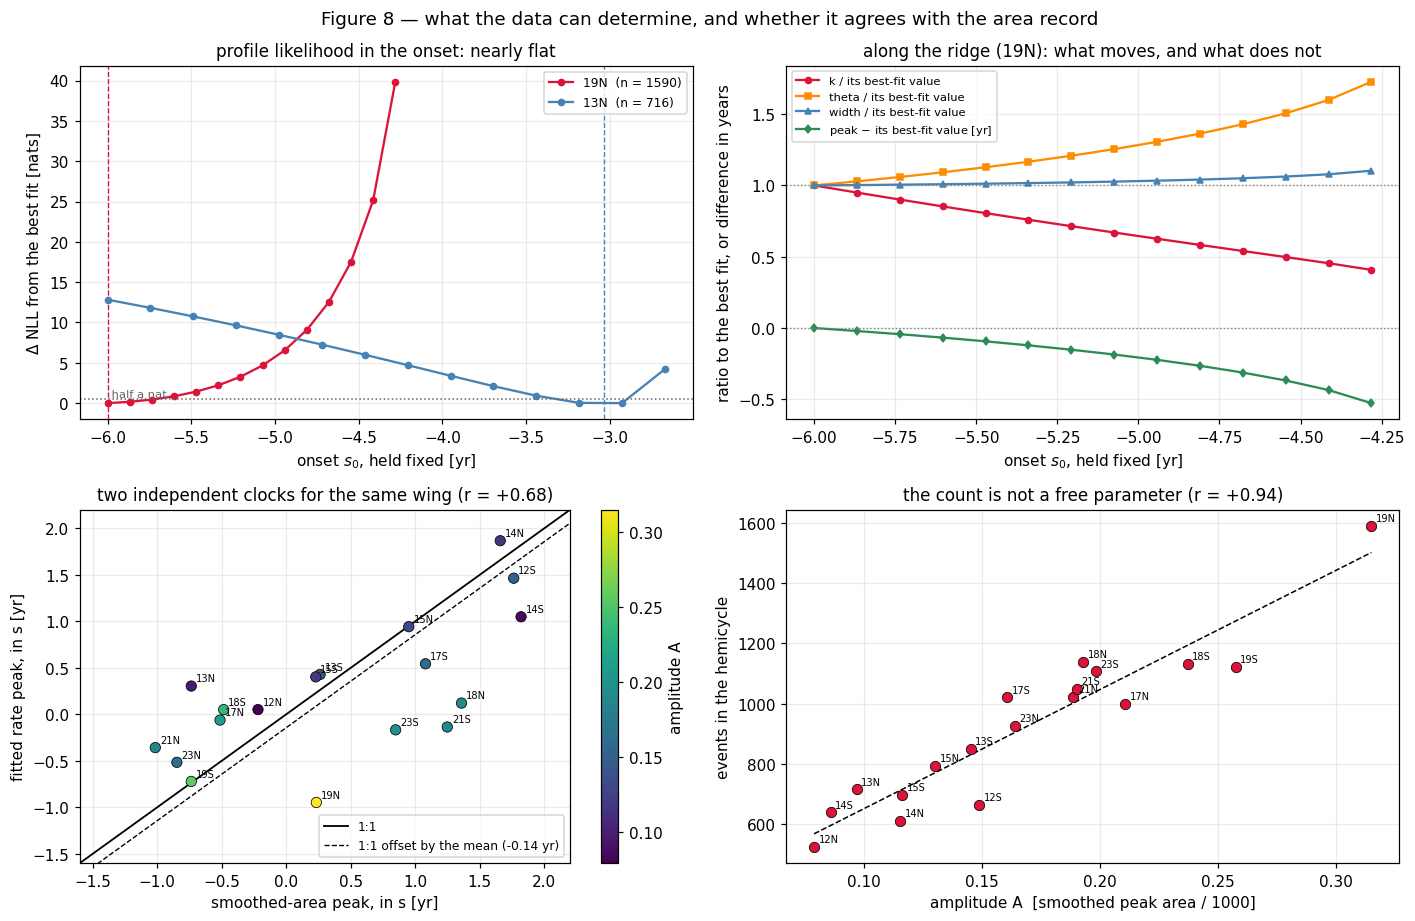

In [59]:
# Given: Figure 8 — what is identifiable, and whether the identifiable part is physically sensible.
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))

ax = axes[0, 0]
for label, colour in zip(PROFILE_LABELS, ("crimson", "steelblue")):
    table = profiles[label]
    ax.plot(table["s_onset"], table["nll"] - table["nll"].min(), "o-", color=colour, ms=4,
            label=f"{label}  (n = {len(EVENTS[label])})")
    fitted_onset = unpack(*FITS[label])[3]
    ax.axvline(fitted_onset, color=colour, lw=0.9, ls="--")
ax.axhline(0.5, color="0.4", lw=1.0, ls=":")
ax.text(S_A, 0.5, " half a nat ", fontsize=7.5, color="0.4", va="bottom")
ax.set_xlabel(r"onset $s_0$, held fixed [yr]")
ax.set_ylabel(r"$\Delta$ NLL from the best fit [nats]")
ax.set_title("profile likelihood in the onset: nearly flat")
ax.legend(fontsize=8)

ax = axes[0, 1]
table = profiles["19N"]
reference = table.loc[table["nll"].idxmin()]
for name, colour, marker in (("k", "crimson", "o"), ("theta", "darkorange", "s"),
                             ("width", "steelblue", "^"), ("s_peak", "seagreen", "d")):
    if name == "s_peak":
        ax.plot(table["s_onset"], table[name] - reference[name], marker + "-", color=colour,
                ms=4, label=r"peak $-$ its best-fit value [yr]")
    else:
        ax.plot(table["s_onset"], table[name] / reference[name], marker + "-", color=colour,
                ms=4, label=f"{name} / its best-fit value")
ax.axhline(1.0, color="0.5", lw=0.9, ls=":")
ax.axhline(0.0, color="0.5", lw=0.9, ls=":")
ax.set_xlabel(r"onset $s_0$, held fixed [yr]")
ax.set_ylabel("ratio to the best fit, or difference in years")
ax.set_title("along the ridge (19N): what moves, and what does not")
ax.legend(fontsize=7.5)

ax = axes[1, 0]
ax.scatter(plausibility["s_peak_area"], plausibility["s_peak"], s=46,
           c=plausibility["A"], cmap="viridis", edgecolors="k", linewidths=0.5, zorder=3)
span = [-1.6, 2.2]
ax.plot(span, span, "k-", lw=1.2, label="1:1")
ax.plot(span, [v + difference.mean() for v in span], "k--", lw=0.9,
        label=f"1:1 offset by the mean ({difference.mean():+.2f} yr)")
for label, row in plausibility.iterrows():
    ax.annotate(label, (row["s_peak_area"], row["s_peak"]), fontsize=6.5,
                xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("smoothed-area peak, in s [yr]")
ax.set_ylabel("fitted rate peak, in s [yr]")
ax.set_xlim(*span)
ax.set_ylim(*span)
ax.set_title(f"two independent clocks for the same wing (r = {PEAK_CORRELATION:+.2f})")
ax.legend(fontsize=8, loc="lower right")
plt.colorbar(ax.collections[0], ax=ax, label="amplitude A")

ax = axes[1, 1]
ax.scatter(plausibility["A"], plausibility["n"], s=46, color="crimson",
           edgecolors="k", linewidths=0.5, zorder=3)
slope, intercept = np.polyfit(plausibility["A"], plausibility["n"], 1)
a_line = np.linspace(plausibility["A"].min(), plausibility["A"].max(), 10)
ax.plot(a_line, slope * a_line + intercept, "k--", lw=1.0)
for label, row in plausibility.iterrows():
    ax.annotate(label, (row["A"], row["n"]), fontsize=6.5, xytext=(3, 3),
                textcoords="offset points")
ax.set_xlabel("amplitude A  [smoothed peak area / 1000]")
ax.set_ylabel("events in the hemicycle")
ax.set_title(f"the count is not a free parameter (r = {COUNT_AMPLITUDE_CORRELATION:+.2f})")
fig.suptitle("Figure 8 — what the data can determine, and whether it agrees with the area record")
plt.tight_layout()
plt.show()

The two clocks agree, but only roughly. The fitted peak and the area peak correlate at about +0.7 across
the 18 wings, with no systematic offset worth speaking of, and a scatter of about 0.7 years. Some of that
scatter is ours — the ridge alone moves a fitted peak by a couple of tenths of a year — and the rest is
real: the moment when the most *groups* emerge is not the same moment as when the most *area* is on the
disk, because big groups and many groups do not peak together. Two measurements of the same wing,
disagreeing by less than a year, from completely different observables, is about as much agreement as
this comparison can honestly deliver.

The lower right panel is the answer to the week's question, and it is a strong yes. The number of
emergences in a hemicycle tracks the amplitude of the smoothed area record at r = +0.94. The sunspot
bell curve really is the rate of this point process — and the thing 1.0 could not do, predicting how many
groups a cycle produces, is apparently within reach from the amplitude alone.

One result we are *not* claiming. The fitted width correlates with amplitude at only about −0.3 across 18
wings, which is far too weak to call with this sample. Stronger cycles being slightly narrower in time is
a real hypothesis, and testing it needs the pooled fit of Week 3, where the width is a shared parameter
with an amplitude dependence rather than 18 independent noisy estimates.

### Dialogue for Section 7 — what varies, and what is even measurable

Nothing to write here. Work this with your tutor before you implement Tasks 18 and 19.

```text
TUTOR DIRECTIVE — Section 7. Work this before the student implements Tasks 18 and 19.

Material: the student has 18 independent four-parameter fits and is about to ask how much a wing's shape
varies from cycle to cycle. They will do two things: profile the likelihood in the onset, holding it
fixed at a range of values and re-maximizing over the other three parameters; and compare the fitted
rate's peak position against the peak of the 12-month-smoothed sunspot area record, which is an
independent measurement of the same wing. Neither has been computed yet.

Work this predictively, and do not state any of the outcomes.

1. Before anything else, get a prediction: of the four fitted quantities, which will vary a lot across
   the 18 hemicycles and which will barely vary? Make them commit, and keep the answer.
2. In the Section 4 table, the fitted onset sits at exactly the lowest value the parameterization allows
   in a majority of the hemicycles. Ask what it means for a fitted parameter to come to rest on the edge
   of its allowed range, and what they would do to find out whether that is a problem. Require a proposed
   diagnostic from the student before you describe the one the notebook uses. Do not tell them the
   likelihood is flat.
3. Push hard on the distinction between "this parameter varies across hemicycles" and "this parameter is
   poorly determined within one hemicycle". These look identical in a scatter plot of fitted values and
   they mean opposite things for Week 03. Then ask them to construct a quantity built out of poorly
   determined parameters that is itself well determined, and to say what would make it so. Bridge towards
   it if they stall; do not supply one.
4. The fitted rate peaks when the most groups emerge; the area record peaks when the most sunspot area is
   on the disk. Ask whether those two should coincide exactly, and require reasons they might not, before
   any number is on the table. Then ask what they would conclude if the two disagreed by five years, and
   what they would conclude if they agreed to within a week.
5. Leave pooling open. Ask what sharing a shape parameter across all 18 wings would buy and what it would
   cost, and what evidence they would want before deciding. Do not resolve it — Week 03 does, and the
   student should arrive there with the question already sharpened rather than answered.

`identifiability`, `profile likelihood` and `emergence rate` are the targets least likely to have been
deployed by this point; prefer them when you choose an anchor.
```

---
## 8 · Where this leaves us

The week's question was whether the sunspot bell curve can be recovered as the rate of a Poisson process.
It can. A four-parameter gamma rate, fitted to event times by maximum likelihood on a fixed window, beats
a constant rate by about 39 nats per hemicycle-year, passes a time-rescaling test with nothing tunable in
it for 17 of 18 hemicycles, and its event count tracks the independently measured area amplitude at
r = +0.94. Week 1's missing half — how many groups emerge, and when — is now a fitted object.

Four things came with it that outlast this notebook.

*The loss.* `Σ log λ − ∫λ` is the loss every model in this program is trained on, classical or neural.
Only λ changes. Week 5's latent field is fitted by minimizing exactly this expression, in two dimensions
instead of one.

*The window, and therefore the mesh.* We fixed `s ∈ [−6, +11]` with a 4001-node mesh, and both are now
frozen for the program. That is not housekeeping: the same 18 fits score −204 nats per hemicycle-year on
this window and −165 on a window four years wider, without a single prediction changing. A likelihood
quoted without its window is not a number anyone can check.

*Two verification habits that survive the move to Phase B.* Refine the mesh and watch the change shrink
by the expected power — which works when there is no closed form to compare against, and from Week 5 there
will not be. And check that the fitted rate's integral over the window equals the observed count, which is
true of any rate model with a free scale and caught the quiet failure in Section 5 that nothing else did.

*A measured argument for pooling.* The rising edge of a wing is observed by about one event in a
thousand, the onset is pinned to the window edge in 11 of 18 fits, and `k`, `θ` and `s₀` trade off against
each other strongly enough that two of the four fitted parameters mean much less than they appear to. The
answer is not a better optimizer; it is to let 18 wings determine jointly what none of them determines
alone. Week 3 shares the shape, re-derives `t0` inside every validation fold, and scores held-out
hemicycles for the first time — at which point "it fits well" has to become "it predicts a cycle it has
never seen".

Carried forward: `s`, the hemispheric cycle as the unit of replication, the fixed window and mesh, the
development set of 18 hemicycles with cycles 16, 20 and 22 sealed, the day-jitter policy for any
time-rescaling test, and the habit of asking whether a parameter was measured before interpreting it.

---
## Before you push: save the conversation

Type `wrap up` in your tutor session. It runs a closure and prints a `HANDOFF` block. Copy that block
and save it as `vocal_handoff.md` in your week 02 submission folder, then push it together with your
completed notebook. The HANDOFF is part of this week's deliverable: the figures show what you computed,
and the HANDOFF is the record of the argument you built around them. It is also what you paste at the
start of next week's session, so that your tutor picks up where you left off instead of starting cold.

If a number came out differently from what you predicted in the session — and at least one of them will —
go back to the tutor, paste the numbers, and take a second HANDOFF. The latest one supersedes the earlier.